# 데이터분석 Mini Project Day1 — EDA (2조)

신약 후보물질 독성 여부 이진분류 데이터(`train.csv`)의 EDA 노트북입니다.

| 항목 | 내용 |
|---|---|
| 데이터 | train.csv 8,349행 × 3,078열 |
| 라벨 | 1 = 독성 없음 (Positive), 0 = 독성 있음 |
| 평가지표 | F1 Score |
| 범위 | 1부: 데이터 EDA(1~9단계) / 2부: 학습 컬럼 선정(10~17단계) / predict_input 비교는 Day2 |

EDA 원칙
- 외부 도메인 가정 없이 제공 데이터 안에서 확인·검증 가능한 항목만 분석
- 라벨로 고른 feature는 인사이트로만 사용하고, 실제 feature 선택은 모델링 단계의 CV fold 안에서 수행
- 소표본 그룹 비율은 Wilson 신뢰구간과 함께 해석
- 입체정보·염을 제거한 parent 분자 기준으로 중복을 정리한 데이터로 통계 계산

실행 환경: `pip install rdkit pandas numpy scipy scikit-learn statsmodels matplotlib seaborn lightgbm`

## 결론 미리보기
- 데이터: 8,349개 분자, fingerprint 3,072비트 + descriptor 4종. 입체·염을 떼면 312행이 중복이고 37그룹은 라벨이 충돌 → 정리 후 8,000행
- 독성과 관련이 큰 변수: clogp(높을수록 독성), TPSA·HBD(극성이 높을수록 비독성), 특정 FCFP·ECFP 부분구조 비트
- 상관·다중공선성 정리: n_heavy·n_N·n_O 제거(VIF 최대 48.4 → 9.2), 범주형이 없어 원핫 인코딩 불필요
- 실험(트리·선형·신경망 3개 모델, 반복 그룹 CV: 1차 조합 → 2차 조정 → 3차 scaffold CV → 4차 필터 기준 0~20% 스윕 → 5차 약한 상관 변수 제외)으로 최종 1,042개 컬럼 선정: ECFP 644 + FCFP 383 + MolWt·clogp·sa_score + RDKit 파생 12
- 선정 이유: 세 모델 모두에서 1위와 표준편차 안으로 차이가 없는 조합 중 컬럼이 가장 적음. PTFP·qed·희귀 비트는 빼도 성능 차이가 없었음
- 최종 컬럼 성능(F1, parent CV): LightGBM 0.818, LogReg 0.786, MLP 0.801 (베이스라인 0.703). 처음 보는 골격 기준(scaffold CV)은 0.762~0.790
- 산출물: train_preprocessed.csv, feature_columns.json, preprocess.py (17단계)

In [1]:
import pandas as pd, numpy as np, warnings
import matplotlib.pyplot as plt, seaborn as sns
from rdkit import Chem, RDLogger
from IPython.display import display
RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 50)
sns.set_theme(style="whitegrid")

train = pd.read_csv("train.csv")
fp_cols = [c for c in train.columns if c.startswith(("ecfp_", "fcfp_", "ptfp_"))]
ecfp_cols = [c for c in fp_cols if c.startswith("ecfp_")]
fcfp_cols = [c for c in fp_cols if c.startswith("fcfp_")]
ptfp_cols = [c for c in fp_cols if c.startswith("ptfp_")]
desc_cols = ["MolWt", "clogp", "sa_score", "qed"]
mols = [Chem.MolFromSmiles(s) for s in train["SMILES"]]
print("SMILES 파싱 실패:", sum(m is None for m in mols))

SMILES 파싱 실패: 0


## 1. 데이터 구조·품질·행 순서 점검
목적: 데이터가 명세와 일치하는지, 분석과 검증을 왜곡하는 구조(결측, 이상값, 정렬)가 있는지 확인

In [2]:
print("shape:", train.shape)
print("결측치 합계:", train.isna().sum().sum())
print("fingerprint 고유값:", np.unique(train[fp_cols].values))
print("dtype:", train.dtypes.value_counts().to_dict())
display(train[desc_cols].describe().T.round(3))
print("sa_score 1~10 범위 밖:", (~train["sa_score"].between(1, 10)).sum())
print("qed 0~1 범위 밖:", (~train["qed"].between(0, 1)).sum())
print("SMILES 길이:", train["SMILES"].str.len().describe()[["min", "50%", "max"]].to_dict(), "/ 원본 문자열 중복:", train["SMILES"].duplicated().sum())

shape: (8349, 3078)
결측치 합계: 0


fingerprint 고유값: [0 1]
dtype: {dtype('int64'): 3073, dtype('float64'): 4, <StringDtype(storage='python', na_value=nan)>: 1}


,count,mean,std,min,25%,50%,75%,max
MolWt,8349.0,443.249,88.876,94.117,383.879,441.522,495.639,1242.488
clogp,8349.0,3.795,1.379,-4.049,2.874,3.735,4.652,9.429
sa_score,8349.0,3.188,0.728,1.282,2.663,3.093,3.594,7.309
qed,8349.0,0.559,0.186,0.024,0.425,0.556,0.701,0.947


sa_score 1~10 범위 밖: 0
qed 0~1 범위 밖: 0
SMILES 길이: {'min': 9.0, '50%': 55.0, 'max': 249.0} / 원본 문자열 중복: 0


,MolWt,label
행 구간(10분위),,
0,301.153,0.556
1,361.380,0.559
2,391.654,0.496
3,418.954,0.492
4,443.879,0.534
5,469.626,0.530
6,494.451,0.510
7,530.764,0.509
8,559.371,0.596


MolWt가 가장 크게 떨어지는 행: 7737 (1242.5 → 201.3)
행 0~7736 (7737행): MolWt 비감소 비율 0.892, 범위 94~1242
행 7737~8348 (612행): MolWt 비감소 비율 0.989, 범위 201~1242


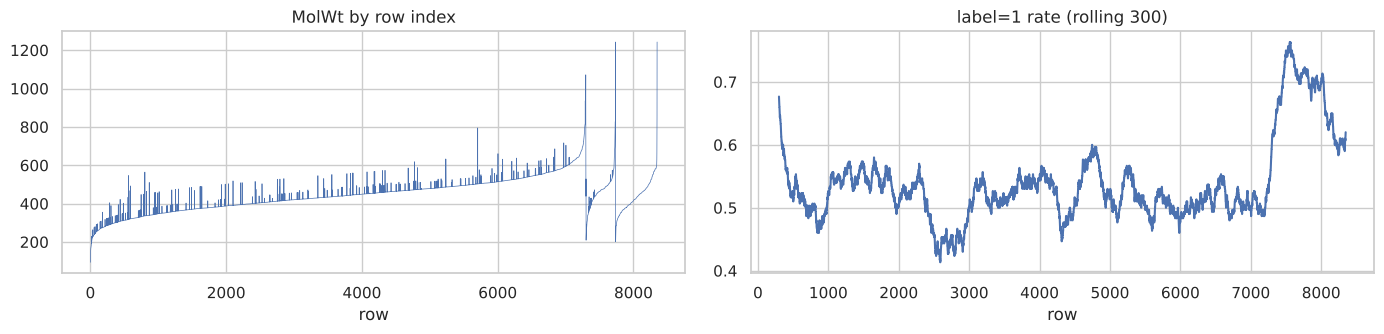

In [3]:
# 행 순서: 정렬 여부와 구간별 라벨 비율
dec = pd.qcut(train.index, 10, labels=False)
display(train.groupby(dec)[["MolWt", "label"]].mean().round(3).rename_axis("행 구간(10분위)"))
# MolWt가 가장 크게 떨어지는 지점 = 정렬 블록 경계
mw = train["MolWt"].values
boundary = int(np.argmin(np.diff(mw))) + 1
print("MolWt가 가장 크게 떨어지는 행:", boundary, f"({mw[boundary-1]:.1f} → {mw[boundary]:.1f})")
for a, b in [(0, boundary), (boundary, len(mw))]:
    seg = mw[a:b]
    print(f"행 {a}~{b-1} ({b-a}행): MolWt 비감소 비율 {(np.diff(seg) >= 0).mean():.3f}, 범위 {seg.min():.0f}~{seg.max():.0f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
ax[0].plot(train["MolWt"].values, lw=0.5); ax[0].set_title("MolWt by row index"); ax[0].set_xlabel("row")
ax[1].plot(train["label"].rolling(300).mean().values); ax[1].set_title("label=1 rate (rolling 300)"); ax[1].set_xlabel("row")
plt.tight_layout(); plt.show()

In [4]:
# 두 번째 블록을 하위 집단으로 비교
train["block2"] = (train.index >= boundary).astype(int)
display(train.groupby("block2")[desc_cols + ["label"]].agg(["mean"]).round(3).droplevel(1, axis=1)
        .assign(n=train["block2"].value_counts().sort_index().values))

,MolWt,clogp,sa_score,qed,label,n
block2,,,,,,
0,443.708,3.821,3.178,0.558,0.536,7737
1,437.439,3.463,3.308,0.577,0.650,612


### 1단계 결과
- 결측 0, fingerprint는 모두 0/1, descriptor 값도 정의 범위 안 → 결측·이상값 처리 불필요
- 행이 두 블록으로 나뉨: 0~7,736행(7,737행)은 MolWt가 대체로 오름차순(비감소 89%), 7,737~8,348행(612행)은 다시 처음부터 오름차순 정렬
- 두 번째 블록은 비독성 비율 0.650으로 첫 블록(0.536)보다 높고, clogp가 낮고(3.46 vs 3.82) sa_score가 높음(3.31 vs 3.18)
- 결정: CV는 반드시 shuffle. 블록이 생긴 이유는 데이터만으로 알 수 없으므로, 모델링 때 블록별 검증 성능을 따로 확인

## 2. 제공 feature 정합성 기록
목적: 제공된 descriptor·fingerprint가 SMILES로부터 어떤 방식으로 계산됐는지 확정해, 추가 feature 생성과 비트 해석의 근거로 사용

In [5]:
from rdkit.Chem import Descriptors, Crippen, QED
from rdkit.Chem import rdFingerprintGenerator as rfg
from rdkit.Contrib.SA_Score import sascorer

s = train.sample(300, random_state=0).index
rows = []
for name, fn in [("MolWt", Descriptors.MolWt), ("clogp", Crippen.MolLogP),
                 ("qed", QED.qed), ("sa_score", sascorer.calculateScore)]:
    v = np.array([fn(mols[i]) for i in s])
    d = np.abs(v - train.loc[s, name].values)
    rows.append((name, d.mean(), d.max(), np.corrcoef(v, train.loc[s, name].values)[0, 1]))
display(pd.DataFrame(rows, columns=["descriptor", "평균 오차", "최대 오차", "상관"]))

,descriptor,평균 오차,최대 오차,상관
0,MolWt,1.134955e-10,3.400015e-08,1.000000
1,clogp,2.517616e-15,9.769963e-15,1.000000
2,qed,2.478495e-10,4.998653e-10,1.000000
3,sa_score,3.686518e-04,1.105955e-01,0.999956


In [6]:
ecfp_gen = rfg.GetMorganGenerator(radius=2, fpSize=1024)
fcfp_gen = rfg.GetMorganGenerator(radius=2, fpSize=1024,
                                  atomInvariantsGenerator=rfg.GetMorganFeatureAtomInvGen())
rows = []
for r in [1, 2, 3]:
    for kind, cols, feat in [("ECFP", ecfp_cols, False), ("FCFP", fcfp_cols, True)]:
        g = rfg.GetMorganGenerator(radius=r, fpSize=1024,
                                   atomInvariantsGenerator=rfg.GetMorganFeatureAtomInvGen() if feat else None)
        X = np.array([g.GetFingerprintAsNumPy(mols[i]) for i in s])
        Y = train.loc[s, cols].values
        rows.append((kind, f"Morgan r={r}", (X == Y).mean(), (X == Y).all(1).mean()))
for kind, fn in [("PTFP", lambda m: Chem.PatternFingerprint(m, fpSize=1024)),
                 ("PTFP", lambda m: Chem.RDKFingerprint(m, fpSize=1024))]:
    X = np.array([list(fn(mols[i])) for i in s]); Y = train.loc[s, ptfp_cols].values
    rows.append((kind, "PatternFingerprint" if len(rows) == 6 else "RDKFingerprint", (X == Y).mean(), (X == Y).all(1).mean()))
display(pd.DataFrame(rows, columns=["제공 fingerprint", "재생성 방식", "비트 일치율", "행 단위 완전 일치율"]).round(4))

,제공 fingerprint,재생성 방식,비트 일치율,행 단위 완전 일치율
0,ECFP,Morgan r=1,0.9782,0.0000
1,FCFP,Morgan r=1,0.9792,0.0000
2,ECFP,Morgan r=2,0.9999,0.9967
3,FCFP,Morgan r=2,1.0000,1.0000
4,ECFP,Morgan r=3,0.9801,0.0000
5,FCFP,Morgan r=3,0.9800,0.0000
6,PTFP,PatternFingerprint,1.0000,1.0000
7,PTFP,RDKFingerprint,0.4854,0.0000


In [7]:
# 염·혼합물, 입체 표기 비율
n_frag = np.array([len(Chem.GetMolFrags(m)) for m in mols])
print("여러 조각(염·혼합물) 행:", (n_frag > 1).sum(), f"({(n_frag > 1).mean():.1%})")
print("조각 수 분포:", pd.Series(n_frag).value_counts().to_dict())
print("예시:", train.loc[n_frag > 1, "SMILES"].head(3).tolist())
print("입체 표기('@') 포함:", f"{train['SMILES'].str.contains('@').mean():.1%}")

여러 조각(염·혼합물) 행: 262 (3.1%)
조각 수 분포: {1: 8087, 2: 237, 3: 16, 5: 5, 4: 3, 9: 1}
예시: ['Cl.Cc1cc(C2NC=NC=C2)c(C)s1', 'Cl.NC[C@H]1C[C@@H]1c2cc(F)ccc2OCC=C', 'Cl.NC[C@H]1C[C@@H]1c2cc(F)ccc2OCCF']
입체 표기('@') 포함: 44.2%


### 2단계 결과
- descriptor 4종 모두 RDKit 계산값 (MolWt·clogp·qed 오차 사실상 0, sa_score는 RDKit Contrib SA Score와 상관 0.99996)
- ECFP = Morgan radius 2, 1,024비트(행 단위 99.7% 일치), FCFP = Morgan feature radius 2(100%), PTFP = RDKit PatternFingerprint(100%)
- 염·혼합물 262행(3.1%), 입체 표기 44.2%
- 결정: RDKit으로 만든 추가 descriptor는 제공값과 같은 기준으로 계산됨. 비트 역해석은 ECFP·FCFP만 수행(PTFP는 부분구조 검색용 해시)

## 3. 중복·입체이성질체·염·라벨 충돌 점검
목적: 같은 분자가 학습·검증에 동시에 들어가 성능이 과대평가되는 것을 막고, 현재 feature로는 구분 불가능한 행의 규모를 파악

parent = 가장 큰 조각(염 제거) + 입체정보 제거 canonical SMILES

In [8]:
def parent(m):
    frags = Chem.GetMolFrags(m, asMols=True)
    big = max(frags, key=lambda x: x.GetNumHeavyAtoms())
    return Chem.MolToSmiles(big, isomericSmiles=False)

train["can"] = [Chem.MolToSmiles(m) for m in mols]
train["can_noiso"] = [Chem.MolToSmiles(m, isomericSmiles=False) for m in mols]
train["parent"] = [parent(m) for m in mols]

rows = []
for key in ["SMILES", "can", "can_noiso", "parent"]:
    g = train.groupby(key)["label"].agg(["nunique", "size"])
    rows.append((key, train[key].duplicated().sum(), (g["size"] > 1).sum(),
                 (g["nunique"] > 1).sum(), g.loc[g["nunique"] > 1, "size"].sum()))
display(pd.DataFrame(rows, columns=["기준", "중복 행", "중복 그룹", "라벨 충돌 그룹", "충돌 그룹 행 수"]))

h = pd.util.hash_pandas_object(train[fp_cols + desc_cols], index=False).values
gh = train.groupby(h)["label"].agg(["nunique", "size"])
print("feature(fp+descriptor) 완전 동일 중복 행:", pd.Series(h).duplicated().sum(),
      "/ 라벨 충돌 그룹:", (gh["nunique"] > 1).sum(), "/ 충돌 행:", gh.loc[gh["nunique"] > 1, "size"].sum())

,기준,중복 행,중복 그룹,라벨 충돌 그룹,충돌 그룹 행 수
0,SMILES,0,0,0,0
1,can,1,1,0,0
2,can_noiso,288,236,34,75
3,parent,312,259,37,81


feature(fp+descriptor) 완전 동일 중복 행: 293 / 라벨 충돌 그룹: 33 / 충돌 행: 73


In [9]:
# 라벨 충돌 예시: 입체 표기만 다른데 라벨이 다른 경우
gp = train.groupby("parent")["label"].agg(["nunique", "size"])
conf = gp[gp["nunique"] > 1].index
display(train.loc[train["parent"].isin(conf[:5]), ["parent", "SMILES", "label"]].sort_values(["parent", "label"]))

,parent,SMILES,label
6530,CC(C)c1cc(C#N)cc2nc(-c3ccc(C(=O)NCC4CCC(c5cccc...,CC(C)c1cc(cc2nc(oc12)c3ccc(cc3)C(=O)NC[C@@H]4C...,0
6531,CC(C)c1cc(C#N)cc2nc(-c3ccc(C(=O)NCC4CCC(c5cccc...,CC(C)c1cc(cc2nc(oc12)c3ccc(cc3)C(=O)NC[C@@H]4C...,1
7189,CC(C)c1cc(C#N)cc2nc(-c3ccc(C(=O)NCC4CN(c5ccc(-...,CC(C)c1cc(cc2nc(oc12)c3ccc(cc3)C(=O)NC[C@H]4CN...,0
7187,CC(C)c1cc(C#N)cc2nc(-c3ccc(C(=O)NCC4CN(c5ccc(-...,CC(C)c1cc(cc2nc(oc12)c3ccc(cc3)C(=O)NC[C@@H]4C...,1
7188,CC(C)c1cc(C#N)cc2nc(-c3ccc(C(=O)NCC4CN(c5ccc(-...,CC(C)c1cc(cc2nc(oc12)c3ccc(cc3)C(=O)NCC4CN(C(=...,1
379,CC(c1cccc(C#N)c1)n1cc(Cl)cc(C(N)=O)c1=N,C[C@H](N1C=C(Cl)C=C(C(=O)N)C1=N)c2cccc(c2)C#N,0
377,CC(c1cccc(C#N)c1)n1cc(Cl)cc(C(N)=O)c1=N,CC(N1C=C(Cl)C=C(C(=O)N)C1=N)c2cccc(c2)C#N,1
378,CC(c1cccc(C#N)c1)n1cc(Cl)cc(C(N)=O)c1=N,C[C@@H](N1C=C(Cl)C=C(C(=O)N)C1=N)c2cccc(c2)C#N,1
4262,CC1CCCN1CCCOc1ccc(N2CCN(C(=O)c3cc(F)cc(F)c3)CC...,C[C@@H]1CCCN1CCCOc2ccc(cc2)N3CCN(CC3=O)C(=O)c4...,0
4269,CC1CCCN1CCCOc1ccc(N2CCN(C(=O)c3cc(F)cc(F)c3)CC...,C[C@H]1CCCN1CCCOc2ccc(cc2)N3CCN(CC3=O)C(=O)c4c...,1


In [10]:
# 이후 통계용 데이터(df): 라벨 충돌 parent 그룹은 제외하고, 나머지는 parent당 1행만 남김
conf_rows = train["parent"].isin(conf).sum()
df = train[~train["parent"].isin(conf)].drop_duplicates("parent").reset_index(drop=True)
print(f"원본 {len(train)}행 → 충돌 그룹 {len(conf)}개({conf_rows}행) 제외 → parent 중복 제거 후 {len(df)}행")

원본 8349행 → 충돌 그룹 37개(81행) 제외 → parent 중복 제거 후 8000행


### 3단계 결과
- 원본 SMILES·canonical 기준 중복은 0~1건이지만, 입체를 떼면 288행, 염까지 떼면 312행(259그룹)이 중복
- parent 기준 라벨 충돌 37그룹(81행): 입체 표기만 다르거나 표기 유무만 다른 분자에서 라벨이 갈림
- fingerprint+descriptor가 완전히 같은데 라벨이 다른 그룹 33개(73행) → 현재 feature로는 원천적으로 구분 불가능한 구간
- 결정: 이후 통계는 충돌 그룹을 빼고 parent당 1행만 남긴 8,000행(df) 기준. 모델링 CV는 parent를 그룹 키로 하는 StratifiedGroupKFold(shuffle=True). 충돌 그룹 처리(제외 또는 다수결)는 모델링 때 확정

## 4. 라벨 분포
목적: 클래스 불균형 정도를 파악하고 F1 베이스라인 설정

,원본 train,정리 후 df
label,,
1,4542.000,4339.000
0,3807.000,3661.000
label=1 비율,0.544,0.542


전부 1(독성 없음)로 예측 시 F1: 0.7033
전부 0으로 예측 시 F1(Positive=1): 0.0


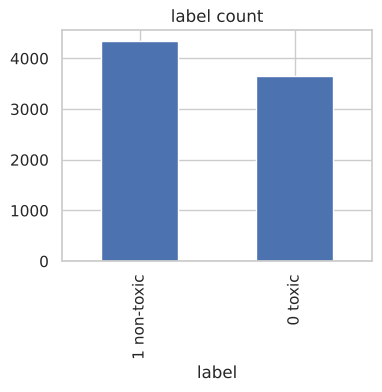

In [11]:
from sklearn.metrics import f1_score
dist = pd.DataFrame({"원본 train": train["label"].value_counts(), "정리 후 df": df["label"].value_counts()})
dist.loc["label=1 비율"] = [train["label"].mean(), df["label"].mean()]
display(dist.round(3))
print("전부 1(독성 없음)로 예측 시 F1:", round(f1_score(df["label"], np.ones(len(df))), 4))
print("전부 0으로 예측 시 F1(Positive=1):", 0.0)

df["label"].map({1: "1 non-toxic", 0: "0 toxic"}).value_counts().plot.bar(figsize=(4, 3), title="label count")
plt.show()

### 4단계 결과
- 정리 후 label=1(독성 없음) 4,339건(54.2%), label=0 3,661건(45.8%) → 심한 불균형 아님
- 전부 1로 예측해도 F1 0.703
- 결정: class_weight는 필수가 아님. F1 0.703을 베이스라인으로 두고, threshold는 검증 데이터에서 F1 최대 지점을 탐색

## 5. Descriptor 4종과 라벨의 관계
목적: MolWt, clogp, sa_score, qed가 독성 여부를 얼마나 구분하는지, 관계가 선형인지 비선형인지 확인

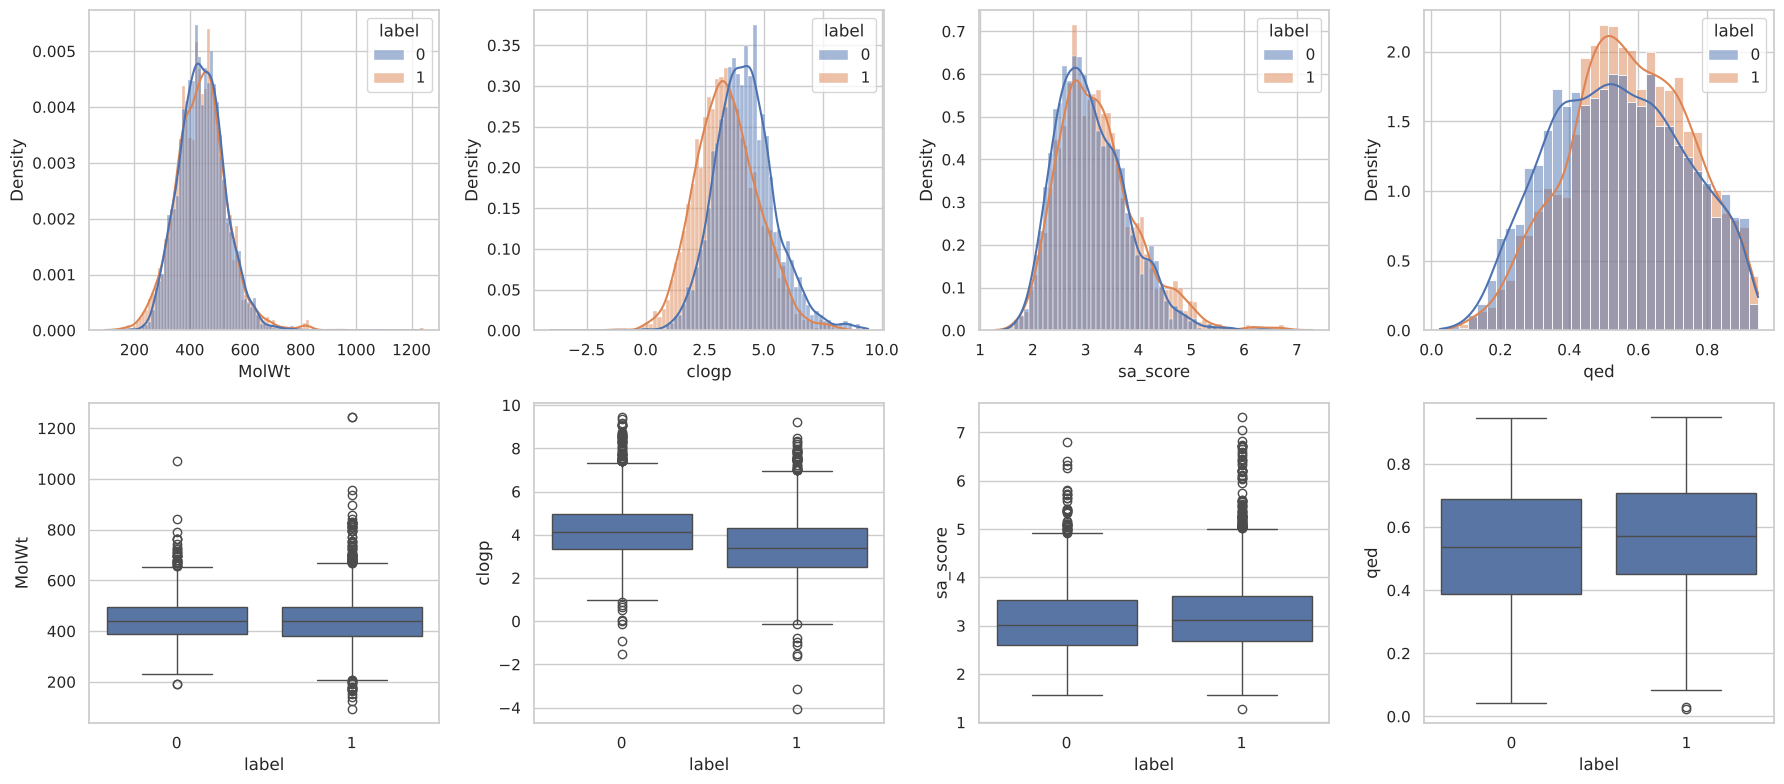

왜도: {'MolWt': 0.596, 'clogp': 0.227, 'sa_score': 0.902, 'qed': -0.054}


In [12]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, c in enumerate(desc_cols):
    sns.histplot(data=df, x=c, hue="label", kde=True, stat="density", common_norm=False, ax=axes[0, i])
    sns.boxplot(data=df, x="label", y=c, ax=axes[1, i])
plt.tight_layout(); plt.show()
print("왜도:", df[desc_cols].skew().round(3).to_dict())

In [13]:
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score
rows = []
for c in desc_cols:
    a, b = df.loc[df.label == 0, c], df.loc[df.label == 1, c]
    rows.append((c, a.median(), b.median(), mannwhitneyu(a, b).pvalue, roc_auc_score(df.label, df[c])))
res5 = pd.DataFrame(rows, columns=["descriptor", "독성(0) 중앙값", "비독성(1) 중앙값", "Mann-Whitney p", "단일 AUC"])
res5["|AUC-0.5|"] = (res5["단일 AUC"] - 0.5).abs()
display(res5.round(4))

,descriptor,독성(0) 중앙값,비독성(1) 중앙값,Mann-Whitney p,단일 AUC,|AUC-0.5|
0,MolWt,440.9500,440.5920,0.2313,0.4922,0.0078
1,clogp,4.1527,3.3771,0.0000,0.3386,0.1614
2,sa_score,3.0099,3.1238,0.0000,0.5405,0.0405
3,qed,0.5377,0.5712,0.0000,0.5499,0.0499


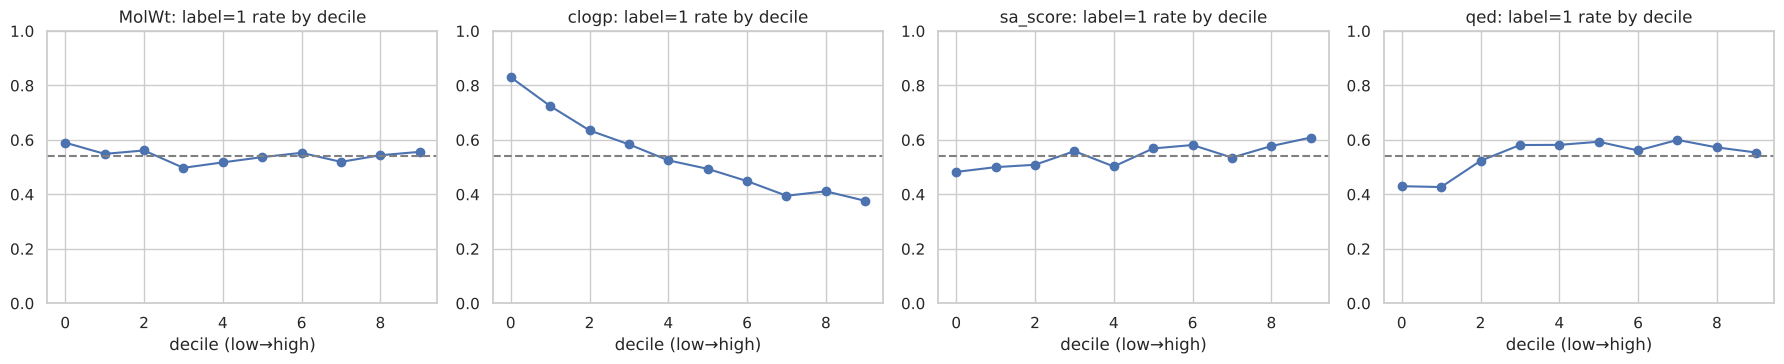

MolWt [0.59, 0.549, 0.561, 0.498, 0.518, 0.537, 0.553, 0.519, 0.544, 0.556]
clogp [0.83, 0.725, 0.635, 0.584, 0.525, 0.494, 0.449, 0.395, 0.411, 0.376]
sa_score [0.482, 0.5, 0.509, 0.559, 0.502, 0.569, 0.581, 0.535, 0.578, 0.609]
qed [0.43, 0.427, 0.523, 0.581, 0.582, 0.593, 0.561, 0.6, 0.572, 0.554]


In [14]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for i, c in enumerate(desc_cols):
    t = df.groupby(pd.qcut(df[c], 10, duplicates="drop"))["label"].agg(["mean", "count"])
    axes[i].plot(range(len(t)), t["mean"], marker="o"); axes[i].axhline(df.label.mean(), ls="--", c="gray")
    axes[i].set_title(f"{c}: label=1 rate by decile"); axes[i].set_xlabel("decile (low→high)"); axes[i].set_ylim(0, 1)
plt.tight_layout(); plt.show()
for c in desc_cols:
    t = df.groupby(pd.qcut(df[c], 10, duplicates="drop"))["label"].agg(["mean", "count"]).round(3)
    print(c, t["mean"].tolist())

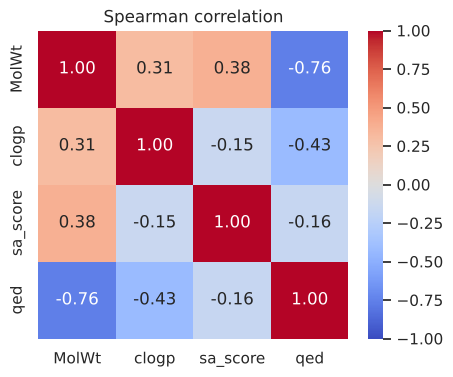

,clogp,qed,sa_score
MolWt 4분위,,,
"(94.116, 383.517]",0.299,0.489,0.519
"(383.517, 440.885]",0.375,0.544,0.553
"(440.885, 495.601]",0.295,0.617,0.560
"(495.601, 1242.488]",0.358,0.602,0.570


In [15]:
plt.figure(figsize=(5, 4))
sns.heatmap(df[desc_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman correlation"); plt.show()

# MolWt와 qed의 상관이 강하므로, MolWt 구간 안에서도 clogp·qed 효과가 남는지 확인
df["mw_bin"] = pd.qcut(df["MolWt"], 4)
out = {c: df.groupby("mw_bin").apply(lambda d: roc_auc_score(d.label, d[c])).round(3) for c in ["clogp", "qed", "sa_score"]}
display(pd.DataFrame(out).rename_axis("MolWt 4분위"))

### 5단계 결과
- clogp가 가장 강한 descriptor: 단일 AUC 0.339(값이 클수록 독성 쪽), 10분위 비독성 비율이 0.83 → 0.38로 거의 단조 감소. MolWt 4분위 안에서도 AUC 0.30~0.38로 유지되어 분자량과 무관한 효과
- qed(AUC 0.550)·sa_score(0.541)는 약한 신호. qed는 MolWt 하위 구간에서 0.49, 상위 구간에서 0.60~0.62로 분자량에 따라 효과가 달라짐
- MolWt는 독성 여부와 차이 없음(p=0.23, AUC 0.492)
- MolWt–qed 스피어만 상관 -0.76으로 강함, 왜도는 모두 1 미만
- 결정: clogp는 핵심 변수 후보. log 변환 불필요. qed와 MolWt는 함께 쓸 때 상호작용을 고려(트리 계열 모델이 유리할 수 있음)

## 6. Fingerprint 분석
목적: 3,072개 비트 중 정보가 없는 비트와 독성과 연관된 비트를 파악하고, 3종 fingerprint의 차이를 확인

,종류,항상0,항상1,1% 미만,99% 초과,분자당 on-bit,on-bit 수 단일 AUC
0,ECFP,0,0,93,1,56.053,0.509
1,FCFP,0,0,422,1,44.819,0.502
2,PTFP,0,49,33,167,433.239,0.502


값이 완전히 같은 컬럼: 106 / 종류별: {'ptfp': 106}


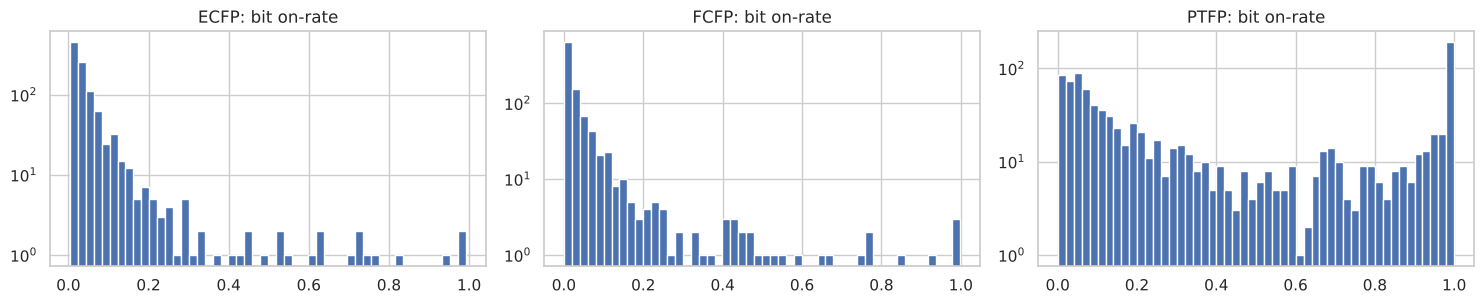

In [16]:
rows = []
for name, cols in [("ECFP", ecfp_cols), ("FCFP", fcfp_cols), ("PTFP", ptfp_cols)]:
    r = df[cols].mean(); n_on = df[cols].sum(axis=1)
    rows.append((name, (r == 0).sum(), (r == 1).sum(), (r < 0.01).sum(), (r > 0.99).sum(),
                 n_on.mean(), roc_auc_score(df.label, n_on)))
display(pd.DataFrame(rows, columns=["종류", "항상0", "항상1", "1% 미만", "99% 초과", "분자당 on-bit", "on-bit 수 단일 AUC"]).round(3))

dup_cols = df[fp_cols].T.duplicated()
print("값이 완전히 같은 컬럼:", dup_cols.sum(), "/ 종류별:", pd.Series(np.array(fp_cols)[dup_cols.values]).str[:4].value_counts().to_dict())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
for i, (name, cols) in enumerate([("ECFP", ecfp_cols), ("FCFP", fcfp_cols), ("PTFP", ptfp_cols)]):
    ax[i].hist(df[cols].mean(), bins=50); ax[i].set_title(f"{name}: bit on-rate"); ax[i].set_yscale("log")
plt.tight_layout(); plt.show()

In [17]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

y = df["label"].values
rows = []
for c in fp_cols:
    on = df[c].values == 1
    rate = on.mean()
    if not 0.01 <= rate <= 0.99:
        continue
    a, b = ((~on) & (y == 0)).sum(), ((~on) & (y == 1)).sum()
    c_, d = (on & (y == 0)).sum(), (on & (y == 1)).sum()
    rows.append((c, rate, d / (c_ + d), b / (a + b), fisher_exact([[a, b], [c_, d]])[1]))
res6 = pd.DataFrame(rows, columns=["bit", "on_rate", "nontox_rate_on", "nontox_rate_off", "p"])
res6["q"] = multipletests(res6["p"], method="fdr_bh")[1]
res6["diff"] = res6["nontox_rate_on"] - res6["nontox_rate_off"]
res6["type"] = res6["bit"].str[:4]
summary = res6.groupby("type").agg(검정비트=("bit", "size"), FDR유의=("q", lambda q: (q < 0.05).sum()))
display(summary)
print("켜지면 비독성 비율이 크게 떨어지는 비트 (독성 쪽 신호)")
display(res6[res6.q < 0.05].sort_values("diff").head(10).round(4))
print("켜지면 비독성 비율이 크게 오르는 비트 (비독성 쪽 신호)")
display(res6[res6.q < 0.05].sort_values("diff", ascending=False).head(10).round(4))

,검정비트,FDR유의
type,,
ecfp,930,409
fcfp,601,280
ptfp,824,380


켜지면 비독성 비율이 크게 떨어지는 비트 (독성 쪽 신호)


,bit,on_rate,nontox_rate_on,nontox_rate_off,p,q,diff,type
1026,fcfp_146,0.0412,0.1121,0.5609,0.0,0.0,-0.4488,fcfp
1186,fcfp_445,0.0325,0.1154,0.5567,0.0,0.0,-0.4413,fcfp
1391,fcfp_780,0.0107,0.1744,0.5464,0.0,0.0,-0.3720,fcfp
387,ecfp_425,0.0542,0.1959,0.5623,0.0,0.0,-0.3664,ecfp
1234,fcfp_526,0.0504,0.1960,0.5607,0.0,0.0,-0.3647,fcfp
933,fcfp_4,0.9899,0.5387,0.9012,0.0,0.0,-0.3625,fcfp
1024,fcfp_143,0.0456,0.2027,0.5586,0.0,0.0,-0.3559,fcfp
700,ecfp_765,0.0558,0.2175,0.5616,0.0,0.0,-0.3441,ecfp
1925,ptfp_505,0.0544,0.2184,0.5610,0.0,0.0,-0.3426,ptfp
1760,ptfp_284,0.0601,0.2266,0.5626,0.0,0.0,-0.3360,ptfp


켜지면 비독성 비율이 크게 오르는 비트 (비독성 쪽 신호)


,bit,on_rate,nontox_rate_on,nontox_rate_off,p,q,diff,type
1002,fcfp_110,0.0235,0.9096,0.5335,0.0,0.0,0.3760,fcfp
1113,fcfp_322,0.0270,0.8935,0.5326,0.0,0.0,0.3609,fcfp
1233,fcfp_525,0.0127,0.8824,0.5380,0.0,0.0,0.3444,fcfp
1411,fcfp_811,0.0131,0.8762,0.5379,0.0,0.0,0.3383,fcfp
976,fcfp_67,0.0165,0.8636,0.5370,0.0,0.0,0.3267,fcfp
509,ecfp_553,0.0259,0.8599,0.5339,0.0,0.0,0.3260,ecfp
2266,ptfp_913,0.0110,0.8636,0.5388,0.0,0.0,0.3248,ptfp
283,ecfp_308,0.0253,0.8465,0.5345,0.0,0.0,0.3120,ecfp
1490,fcfp_953,0.0149,0.8487,0.5377,0.0,0.0,0.3110,fcfp
611,ecfp_663,0.0217,0.8448,0.5357,0.0,0.0,0.3092,ecfp


독성 쪽 상위 ECFP 비트
  ecfp_425: on_rate=0.054, 켜졌을 때 비독성 비율=0.196, 꺼졌을 때=0.562


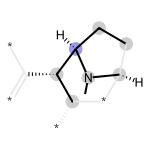

  ecfp_765: on_rate=0.056, 켜졌을 때 비독성 비율=0.217, 꺼졌을 때=0.562


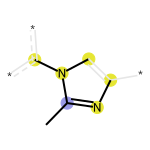

  ecfp_158: on_rate=0.063, 켜졌을 때 비독성 비율=0.244, 꺼졌을 때=0.562


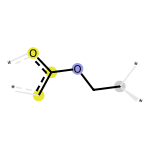

비독성 쪽 상위 ECFP 비트
  ecfp_553: on_rate=0.026, 켜졌을 때 비독성 비율=0.860, 꺼졌을 때=0.534


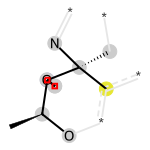

  ecfp_308: on_rate=0.025, 켜졌을 때 비독성 비율=0.847, 꺼졌을 때=0.534


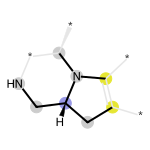

  ecfp_663: on_rate=0.022, 켜졌을 때 비독성 비율=0.845, 꺼졌을 때=0.536


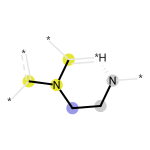

In [18]:
# 중요 ECFP 비트의 부분구조 확인 (독성 쪽 상위 3개, 비독성 쪽 상위 3개)
from rdkit.Chem import Draw

def bit_example(bit_name, gen=ecfp_gen, cols=ecfp_cols):
    bit = int(bit_name.split("_")[1])
    for smi in df.loc[df[bit_name] == 1, "SMILES"].head(30):
        m = Chem.MolFromSmiles(smi)
        ao = rfg.AdditionalOutput(); ao.AllocateBitInfoMap()
        gen.GetFingerprint(m, additionalOutput=ao)
        info = ao.GetBitInfoMap()
        if bit in info:
            return Draw.DrawMorganBit(m, bit, info, useSVG=False)
    return None

ec = res6[(res6.type == "ecfp") & (res6.q < 0.05)]
for title, bits in [("독성 쪽 상위 ECFP 비트", ec.sort_values("diff").head(3)),
                    ("비독성 쪽 상위 ECFP 비트", ec.sort_values("diff", ascending=False).head(3))]:
    print(title)
    for _, r in bits.iterrows():
        print(f"  {r.bit}: on_rate={r.on_rate:.3f}, 켜졌을 때 비독성 비율={r.nontox_rate_on:.3f}, 꺼졌을 때={r.nontox_rate_off:.3f}")
        img = bit_example(r.bit)
        if img is not None:
            display(img)

### 6단계 결과
- 항상 0인 비트는 없음. 1% 미만 비트는 ECFP 93개, FCFP 422개. PTFP는 항상 1인 비트 49개, 99% 초과 167개
- 값이 완전히 같은 컬럼 106개는 모두 PTFP
- 분자당 on-bit 수는 독성과 무관(AUC 0.50~0.51)
- FDR 유의 비트: ECFP 409개, FCFP 280개, PTFP 380개로 세 종류 모두 신호가 많음
- 가장 강한 비트는 FCFP에 몰려 있음: 예) fcfp_146은 4.1% 분자에서 켜지는데, 켜지면 비독성 비율 11% vs 꺼지면 56%
- 결정: 모델링 전 무정보(1% 미만·99% 초과) 비트와 PTFP 중복 컬럼 106개 제거. 비트 선택은 fold 안에서 수행하고, ECFP·FCFP·PTFP 조합별 성능을 비교

## 7. 구조 유사도 분석
목적: 구조가 비슷한 분자끼리 독성 여부도 비슷한지 데이터로 확인 (제공 ECFP 기준 Tanimoto, parent 중복 정리 후 df에서 계산)

최근접 이웃 라벨 일치율: 0.7571
최근접 이웃 유사도 중앙값: 0.791


,mean,count
최근접 이웃 유사도,,
"(0.0, 0.3]",0.639,144
"(0.3, 0.5]",0.651,518
"(0.5, 0.7]",0.745,1182
"(0.7, 0.9]",0.767,5612
"(0.9, 0.999]",0.791,493
"(0.999, 1.01]",1.000,51


activity cliff 후보(유사도 > 0.8, 라벨 다름): 783


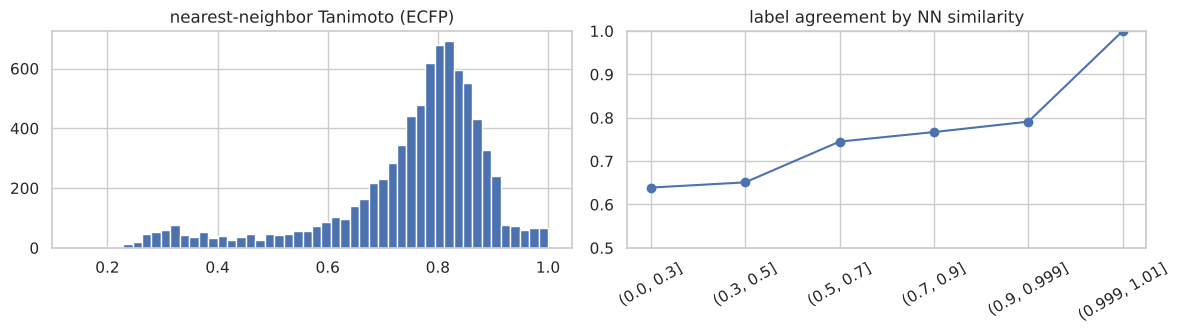

In [19]:
E = df[ecfp_cols].values.astype(np.float32); cnt = E.sum(1)
nn_idx, nn_sim = np.zeros(len(E), int), np.zeros(len(E))
for s0 in range(0, len(E), 1000):
    inter = E[s0:s0+1000] @ E.T
    sim = inter / (cnt[s0:s0+1000, None] + cnt[None] - inter + 1e-9)
    sim[np.arange(sim.shape[0]), np.arange(s0, s0 + sim.shape[0])] = -1
    nn_idx[s0:s0+1000], nn_sim[s0:s0+1000] = sim.argmax(1), sim.max(1)

y = df["label"].values
df["nn_sim"], df["nn_agree"] = nn_sim, (y[nn_idx] == y).astype(int)
print("최근접 이웃 라벨 일치율:", round(df["nn_agree"].mean(), 4))
print("최근접 이웃 유사도 중앙값:", round(np.median(nn_sim), 3))
t7 = df.groupby(pd.cut(df["nn_sim"], [0, .3, .5, .7, .9, .999, 1.01]))["nn_agree"].agg(["mean", "count"]).round(3)
display(t7.rename_axis("최근접 이웃 유사도"))
cliff = (df["nn_sim"] > 0.8) & (df["nn_agree"] == 0)
print("activity cliff 후보(유사도 > 0.8, 라벨 다름):", cliff.sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(nn_sim, bins=50); ax[0].set_title("nearest-neighbor Tanimoto (ECFP)")
ax[1].plot(range(len(t7)), t7["mean"], marker="o"); ax[1].set_xticks(range(len(t7))); ax[1].set_xticklabels([str(i) for i in t7.index], rotation=30)
ax[1].set_title("label agreement by NN similarity"); ax[1].set_ylim(0.5, 1)
plt.tight_layout(); plt.show()

서로 다른 activity cliff 쌍: 514
sim=0.984 | label 1: COc1ccc(cc1)[C@@H](C)N[C@@H]2CC[C@@H](C(=O)N3CCC(CC3)(C(=O)N4CCCC4)c5ccccc5)C(C)(C)C2  vs  label 0: COc1ccc(cc1)[C@@H](C)N[C@@H]2CC[C@@H](C(=O)N3CCC(CC3)(C(=O)N4CCCCC4)c5ccccc5)C(C)(C)C2
sim=0.983 | label 0: OC=O.O=C(N1CCN(C(=O)C1)c2ccc(OC3CCN(CC3)C4CCC4)cc2)c5ccc(cc5)C#N  vs  label 1: OC=O.O=C(N1CCN(C(=O)C1)c2ccc(OC3CCN(CC3)C4CCCC4)cc2)c5ccc(cc5)C#N
sim=0.982 | label 1: OC=O.Fc1cc(F)cc(c1)C(=O)N2CCN(C(=O)C2)c3ccc(OC4CCN(CC4)C5CCC5)cc3  vs  label 0: OC=O.Fc1cc(F)cc(c1)C(=O)N2CCN(C(=O)C2)c3ccc(OC4CCN(CC4)C5CCCC5)cc3


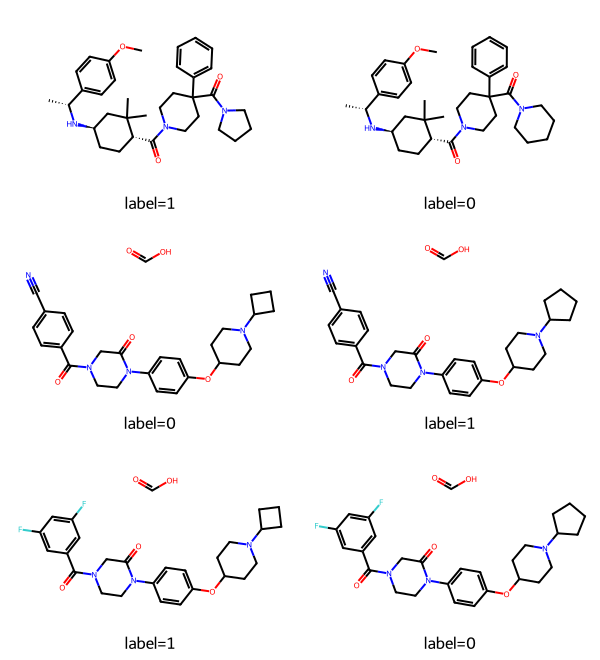

In [20]:
# activity cliff 예시: 구조는 매우 비슷한데 라벨이 다른 쌍
cp = df[cliff].assign(j=nn_idx[cliff.values])
cp["pair"] = [tuple(sorted((i, j))) for i, j in zip(cp.index, cp["j"])]
cp = cp.drop_duplicates("pair")
print("서로 다른 activity cliff 쌍:", len(cp))
ex = cp.sort_values("nn_sim", ascending=False).head(3)
pairs = []
for i, r in ex.iterrows():
    j = int(r.j)
    pairs += [Chem.MolFromSmiles(df.at[i, "SMILES"]), Chem.MolFromSmiles(df.at[j, "SMILES"])]
    print(f"sim={r.nn_sim:.3f} | label {df.at[i,'label']}: {df.at[i,'SMILES']}  vs  label {df.at[j,'label']}: {df.at[j,'SMILES']}")
display(Draw.MolsToGridImage(pairs, molsPerRow=2, subImgSize=(300, 220),
        legends=[f"label={df.at[k,'label']}" for i, r in ex.iterrows() for k in (i, int(r.j))]))

### 7단계 결과
- 최근접 이웃 라벨 일치율 0.757, 최근접 유사도 중앙값 0.791 → 비슷한 화합물 계열이 많이 모인 데이터
- 유사도가 높을수록 일치율이 올라감: 0.3 이하 0.64 → 0.7~0.9 구간 0.77 → 0.9 이상 0.79
- 유사도 0.8 초과인데 라벨이 다른 activity cliff 쌍 514개. 예시처럼 고리 하나의 크기(피롤리딘 ↔ 피페리딘)만 달라도 라벨이 바뀌는 경우가 있음
- 결정: Tanimoto KNN을 베이스라인으로 사용. activity cliff 구간은 모델이 가장 틀리기 쉬운 구간으로 오분류 분석 때 확인

## 8. Scaffold 분석
목적: 골격(Murcko scaffold) 단위로 데이터와 라벨이 편중돼 있는지 확인

In [21]:
from rdkit.Chem.Scaffolds import MurckoScaffold
df["scaffold"] = [MurckoScaffold.MurckoScaffoldSmiles(mol=Chem.MolFromSmiles(s)) for s in df["SMILES"]]
sc = df.groupby("scaffold")["label"].agg(["count", "mean"]).sort_values("count", ascending=False)
print("scaffold 수:", len(sc), "/ 단독 scaffold:", (sc["count"] == 1).sum(), f"({(sc['count']==1).mean():.1%})")
print("상위 20개 scaffold가 차지하는 비중:", round(sc["count"].head(20).sum() / len(df), 3))
big = sc[sc["count"] >= 5]
pure = big[(big["mean"] == 0) | (big["mean"] == 1)]
print(f"5개 이상 scaffold: {len(big)}개({big['count'].sum()}행) / 라벨 한쪽뿐: {len(pure)}개({pure['count'].sum()}행)")
display(sc.head(15).round(3))

scaffold 수: 4145 / 단독 scaffold: 2948 (71.1%)
상위 20개 scaffold가 차지하는 비중: 0.07
5개 이상 scaffold: 302개(2848행) / 라벨 한쪽뿐: 108개(899행)


,count,mean
scaffold,,
O=C1COc2ccc(CNC34CCC(CCc5ccnc6cccnc56)(CC3)OC4)nc2N1,90,0.122
c1ccc(Oc2ccccc2)cc1,48,0.083
c1ccccc1,41,0.220
c1ccc(C2CCc3ccc4[nH]cnc4c3O2)cc1,31,0.742
C1=C(c2ccccc2)c2ccccc2OC12CCNCC2,29,0.414
C1=C(CN2CCOCC2)NC(c2nccs2)=NC1c1ccccc1,26,0.731
c1ccc(N2CCC3CN(CCCSc4nnc(-c5cnccn5)[nH]4)CC32)cc1,25,0.000
O=C(c1ccccc1)N1CCC(CCN2C3CCC2CC(n2cnc4ccccc42)C3)(c2ccccc2)CC1,24,0.750
c1ccc(C23CC2CN(CCCSc2nnc(-c4cnco4)[nH]2)C3)cc1,24,0.000


5개 이상 scaffold의 평균 순도(가중): 0.817 / 무작위 기대치: 0.542


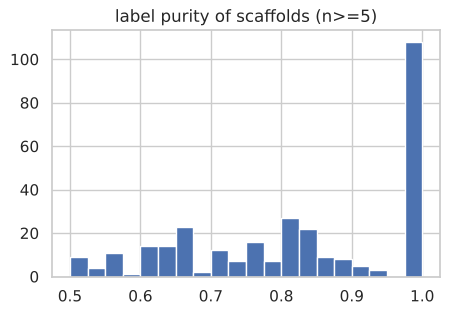

같은 scaffold 이웃: 4011 개, 일치율 0.777
다른 scaffold 이웃: 3989 개, 일치율 0.737


In [22]:
# scaffold 크기별 '라벨 순도' 분포: max(p, 1-p)
big = big.assign(purity=np.maximum(big["mean"], 1 - big["mean"]))
print("5개 이상 scaffold의 평균 순도(가중):", round(np.average(big["purity"], weights=big["count"]), 3),
      "/ 무작위 기대치:", round(max(df.label.mean(), 1 - df.label.mean()), 3))
plt.figure(figsize=(5, 3.2)); plt.hist(big["purity"], bins=20); plt.title("label purity of scaffolds (n>=5)"); plt.show()

# 최근접 이웃이 다른 scaffold일 때도 라벨 일치율이 유지되는지
same = df["scaffold"].values[nn_idx] == df["scaffold"].values
print("같은 scaffold 이웃:", same.sum(), "개, 일치율", round(df["nn_agree"][same].mean(), 3))
print("다른 scaffold 이웃:", (~same).sum(), "개, 일치율", round(df["nn_agree"][~same].mean(), 3))

### 8단계 결과
- scaffold 4,145개 중 71%가 분자 1개짜리, 상위 20개 scaffold 비중은 7%로 특정 골격 쏠림은 크지 않음
- 하지만 5개 이상 scaffold 302개 중 108개(899행)가 한 라벨로만 구성되고, 가중 평균 라벨 순도 0.817로 무작위 기대치(0.542)보다 훨씬 높음 → 골격 단위로 독성 여부가 크게 갈림
- 이웃이 같은 scaffold일 때 일치율 0.777, 다른 scaffold일 때도 0.737로 크게 떨어지지 않음 → 골격 암기만이 아니라 구조 일반화 신호도 있음
- 결정: 랜덤(parent 그룹) CV와 scaffold 그룹 CV를 둘 다 돌려 점수 차이를 비교. 최종 검증 방식은 Day2에 predict_input의 scaffold 겹침 비율을 보고 결정

## 9. SMILES 파생 변수 탐색
목적: 제공 feature에 없는 구조 정보를 SMILES에서 계산해 라벨과의 연관을 확인 (모델링 feature 후보 탐색)

In [23]:
from rdkit.Chem import rdMolDescriptors
from statsmodels.stats.proportion import proportion_confint

def smi_feats(smi):
    m = Chem.MolFromSmiles(smi)
    atoms = [a.GetSymbol() for a in m.GetAtoms()]
    return {
        "n_heavy": m.GetNumHeavyAtoms(),
        "is_salt": int(len(Chem.GetMolFrags(m)) > 1),
        "has_stereo_tag": int("@" in smi),
        "n_halogen": sum(a in ("F", "Cl", "Br", "I") for a in atoms),
        "n_N": atoms.count("N"), "n_O": atoms.count("O"), "n_S": atoms.count("S"),
        "abs_charge": sum(abs(a.GetFormalCharge()) for a in m.GetAtoms()),
        "n_ring": rdMolDescriptors.CalcNumRings(m),
        "n_arom_ring": rdMolDescriptors.CalcNumAromaticRings(m),
        "frac_csp3": rdMolDescriptors.CalcFractionCSP3(m),
        "TPSA": rdMolDescriptors.CalcTPSA(m),
        "HBD": rdMolDescriptors.CalcNumHBD(m),
        "HBA": rdMolDescriptors.CalcNumHBA(m),
        "n_rotb": rdMolDescriptors.CalcNumRotatableBonds(m),
    }

sf = pd.DataFrame([smi_feats(s) for s in df["SMILES"]])
auc9 = pd.Series({c: roc_auc_score(df.label, sf[c]) for c in sf.columns}, name="단일 AUC").to_frame()
auc9["|AUC-0.5|"] = (auc9["단일 AUC"] - 0.5).abs()
auc9["clogp와 Spearman"] = [sf[c].corr(df["clogp"], method="spearman") for c in sf.columns]
display(auc9.sort_values("|AUC-0.5|", ascending=False).round(3))

,단일 AUC,|AUC-0.5|,clogp와 Spearman
TPSA,0.638,0.138,-0.358
n_O,0.627,0.127,-0.245
HBD,0.590,0.090,-0.177
HBA,0.565,0.065,-0.334
n_arom_ring,0.450,0.050,0.361
n_ring,0.450,0.050,0.174
n_rotb,0.452,0.048,0.183
has_stereo_tag,0.540,0.040,-0.072
n_N,0.527,0.027,-0.188
n_halogen,0.479,0.021,0.247


In [24]:
def rate_ci(series_key, label):
    out = []
    for k, s_ in label.groupby(series_key):
        lo, hi = proportion_confint(s_.sum(), len(s_), method="wilson")
        out.append((k, len(s_), s_.mean(), lo, hi))
    return pd.DataFrame(out, columns=["값", "n", "비독성 비율", "CI 하한", "CI 상한"]).round(3)

print("전체 비독성 비율:", round(df.label.mean(), 3))
for c in ["is_salt", "has_stereo_tag"]:
    print(c); display(rate_ci(sf[c], df["label"]))
for c in ["n_halogen", "n_arom_ring", "HBD"]:
    print(c, "(4 이상은 4로 묶음)"); display(rate_ci(sf[c].clip(upper=4), df["label"]))

전체 비독성 비율: 0.542
is_salt


,값,n,비독성 비율,CI 하한,CI 상한
0,0,7764,0.539,0.528,0.550
1,1,236,0.648,0.585,0.706


has_stereo_tag


,값,n,비독성 비율,CI 하한,CI 상한
0,0,4608,0.508,0.494,0.522
1,1,3392,0.589,0.572,0.605


n_halogen (4 이상은 4로 묶음)


,값,n,비독성 비율,CI 하한,CI 상한
0,0,3388,0.570,0.553,0.587
1,1,1869,0.514,0.491,0.536
2,2,1010,0.538,0.507,0.568
3,3,1190,0.513,0.485,0.542
4,4,543,0.541,0.499,0.583


n_arom_ring (4 이상은 4로 묶음)


,값,n,비독성 비율,CI 하한,CI 상한
0,0,81,0.901,0.817,0.949
1,1,663,0.671,0.635,0.706
2,2,2431,0.553,0.533,0.573
3,3,3211,0.523,0.506,0.540
4,4,1614,0.494,0.469,0.518


HBD (4 이상은 4로 묶음)


,값,n,비독성 비율,CI 하한,CI 상한
0,0,1912,0.387,0.365,0.409
1,1,3139,0.564,0.546,0.581
2,2,1871,0.630,0.608,0.652
3,3,799,0.598,0.564,0.632
4,4,279,0.620,0.562,0.675


### 9단계 결과
- 극성 관련 변수가 clogp 다음으로 강한 신호(qed·sa_score보다 강함): TPSA AUC 0.638, 산소 원자 수 0.627, HBD 0.590, HBA 0.565 (값이 클수록 비독성 쪽)
- HBD 0개 분자의 비독성 비율 0.387 vs 1개 이상 0.56~0.63, 방향족 고리 0개 0.90(81개) → 4개 이상 0.49로 감소
- TPSA와 clogp의 상관은 -0.36으로 중간 수준이라 clogp와 별도 정보가 남아 있음
- 염 포함(0.648, CI 0.585~0.706)과 입체 표기 포함(0.589, CI 0.572~0.605)은 신뢰구간이 전체와 겹치지 않아 우연이 아닌 차이. 단, 단일 AUC는 0.54 이하로 작음
- 할로겐 수·전하·황 원자 수는 신호가 거의 없음
- 결정: 파생 변수를 feature 후보로 두고, 서로 겹치는지는 10단계에서 확인한 뒤 13단계 조합 실험으로 효과 비교

---
# 2부. 모델 학습용 컬럼 선정

1부(1~9단계)는 데이터가 어떻게 생겼는지와 각 변수가 독성과 어떤 관계인지를 봤습니다. 2부는 그 결과를 바탕으로 실제 학습에 넣을 컬럼을 정합니다.

| 단계 | 질문 |
|---|---|
| 10 | 변수끼리 겹치거나 다른 변수에서 계산되는 변수가 있는가(10-1), 정리된 변수가 독성과 얼마나 상관이 있는가(10-2, 5차 실험 포함) |
| 11 | 인코딩이나 변환이 필요한 컬럼이 있는가 |
| 12 | fingerprint 3,072비트를 어떤 형태로 쓸 것인가 |
| 13 | 어떤 데이터셋 조합이 모델 종류와 관계없이 안정적으로 좋은가 (1차 조합 실험) |
| 14 | 1차 실험 기준 잠정 선정 컬럼 |
| 15 | 2차 실험: 필터 기준·qed·다중공선성 정리 효과 / 15-1 4차 실험: 필터 기준 0~20% 스윕 |
| 16 | 3차 실험: scaffold CV 재검증 |
| 17 | 최종 컬럼 선정과 전처리 파일 저장 |

특징 선택에서 지킨 원칙
- 과적합 방지: 한 번의 검증 분할이 아니라 같은 분자(parent)를 같은 fold에 묶는 5-fold 그룹 CV를 seed 2개로 반복(총 10번)해 평균 ± 표준편차로 비교
- 모델 의존성 방지: 트리(LightGBM)·선형(로지스틱 회귀)·신경망(MLP) 세 계열에서 모두 좋은 조합을 선택
- 다중공선성 사전 정리: 조합 실험 전에 의미가 겹치는 변수를 먼저 정리(10단계)

## 10. 상관관계·다중공선성·파생 관계 점검
목적
- 10-1: descriptor 4종과 9단계 RDKit 파생 15개 중 서로 거의 같은 정보이거나 다른 변수로 계산되는 변수를 찾아 조합 실험 전에 정리
- 10-2: 각 특성이 독성(label)과 얼마나 직선적으로 같이 움직이는지 상관계수로 확인 (10-1에서 제거한 변수도 비교용으로 함께 표시)

### 10-1. 특성끼리의 상관·다중공선성

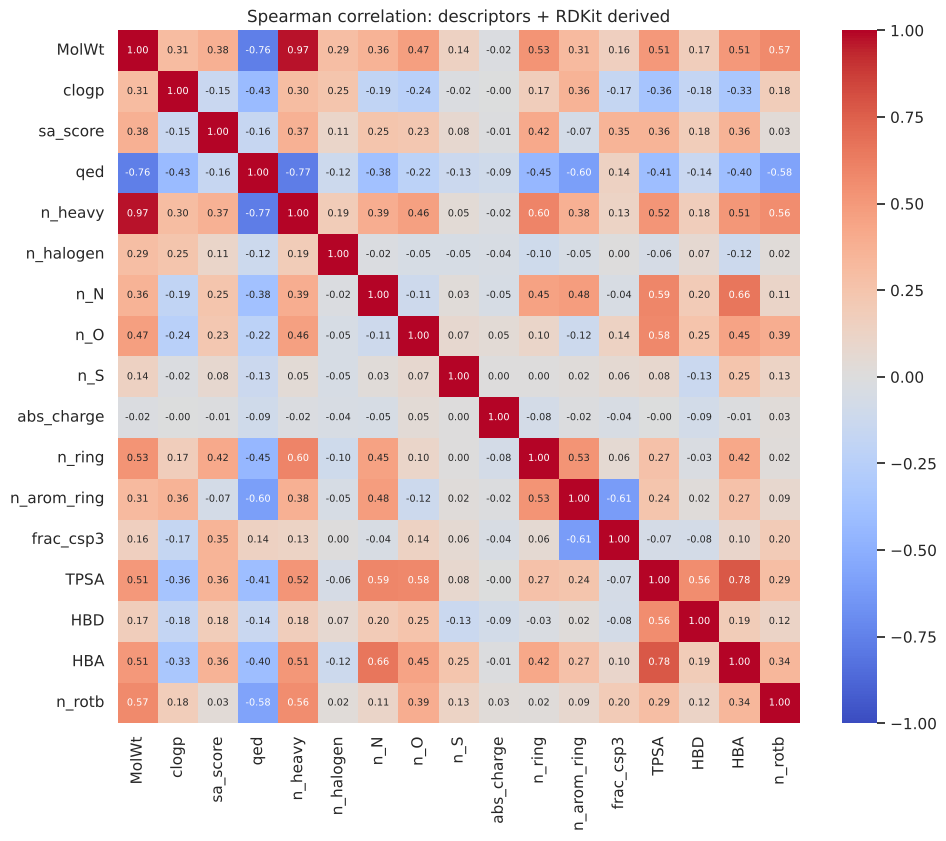

,변수 A,변수 B,Spearman
1,MolWt,n_heavy,0.972
3,TPSA,HBA,0.776
2,qed,n_heavy,-0.767
0,MolWt,qed,-0.760


In [25]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression

binary_cols = ["is_salt", "has_stereo_tag"]
cont = pd.concat([df[desc_cols], sf.drop(columns=binary_cols)], axis=1)

C = cont.corr(method="spearman")
plt.figure(figsize=(11, 9))
sns.heatmap(C, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Spearman correlation: descriptors + RDKit derived"); plt.show()

pairs = [(a, b, C.loc[a, b]) for i, a in enumerate(C.columns) for b in C.columns[i+1:] if abs(C.loc[a, b]) >= 0.7]
display(pd.DataFrame(pairs, columns=["변수 A", "변수 B", "Spearman"]).sort_values("Spearman", key=abs, ascending=False).round(3))

In [26]:
def vif_table(cols):
    Z = (cont[cols] - cont[cols].mean()) / cont[cols].std()
    Z = Z.assign(const=1.0)
    return pd.Series({c: variance_inflation_factor(Z.values, i) for i, c in enumerate(Z.columns) if c != "const"}).sort_values(ascending=False)

vif_before = vif_table(list(cont.columns))
print("정리 전 VIF 상위"); display(vif_before.head(8).round(1).to_frame("VIF"))

정리 전 VIF 상위


,VIF
MolWt,48.4
n_heavy,44.4
TPSA,18.9
n_O,15.9
n_N,15.5
n_arom_ring,9.1
HBA,6.1
n_ring,5.1


In [27]:
# 파생 관계 확인
r_mw = cont["MolWt"].corr(cont["n_heavy"], method="spearman")
r2_tpsa = LinearRegression().fit(cont[["n_N", "n_O"]], cont["TPSA"]).score(cont[["n_N", "n_O"]], cont["TPSA"])
print(f"MolWt vs n_heavy Spearman: {r_mw:.3f}")
print(f"TPSA를 n_N + n_O로 선형 회귀했을 때 R²: {r2_tpsa:.3f}")

# qed는 RDKit 정의상 8개 속성으로 계산되는 지표 → 실제로 그 속성들로 얼마나 설명되는지 확인
from rdkit.Chem import QED
props = pd.DataFrame([QED.properties(Chem.MolFromSmiles(s))._asdict() for s in df["SMILES"]])
r2_qed = LinearRegression().fit(props, df["qed"]).score(props, df["qed"])
print("qed 계산에 쓰이는 속성:", list(props.columns))
print(f"qed를 그 8개 속성으로 선형 회귀했을 때 R²: {r2_qed:.3f}")
print("속성 MW = MolWt 상관:", round(np.corrcoef(props.MW, df.MolWt)[0, 1], 4),
      "/ ALOGP = clogp:", round(np.corrcoef(props.ALOGP, df.clogp)[0, 1], 4),
      "/ PSA = TPSA:", round(np.corrcoef(props.PSA, sf.TPSA)[0, 1], 4))

MolWt vs n_heavy Spearman: 0.972
TPSA를 n_N + n_O로 선형 회귀했을 때 R²: 0.845


qed 계산에 쓰이는 속성: ['MW', 'ALOGP', 'HBA', 'HBD', 'PSA', 'ROTB', 'AROM', 'ALERTS']
qed를 그 8개 속성으로 선형 회귀했을 때 R²: 0.853
속성 MW = MolWt 상관: 1.0 / ALOGP = clogp: 1.0 / PSA = TPSA: 1.0


In [28]:
drop_collinear = ["n_heavy", "n_N", "n_O"]
cont_after = [c for c in cont.columns if c not in drop_collinear]
vif_after = vif_table(cont_after)
comp = pd.DataFrame({"정리 전": vif_before, "정리 후": vif_after}).round(1).sort_values("정리 전", ascending=False)
display(comp)
print("정리 후 최대 VIF:", round(vif_after.max(), 1))

,정리 전,정리 후
MolWt,48.4,8.7
n_heavy,44.4,NaN
TPSA,18.9,9.2
n_O,15.9,NaN
n_N,15.5,NaN
n_arom_ring,9.1,6.5
HBA,6.1,5.0
n_ring,5.1,4.7
clogp,4.7,3.5
frac_csp3,4.4,3.5


정리 후 최대 VIF: 9.2


### 10-1 결과
| 확인 항목 | 수치 | 판단 |
|---|---|---|
| MolWt vs n_heavy(무거운 원자 수) | Spearman 0.972, VIF 48.4 / 44.4 | 사실상 같은 정보 → n_heavy 제거 (제공 컬럼 MolWt 유지) |
| TPSA vs n_N·n_O(질소·산소 수) | TPSA의 84.5%가 두 변수로 설명됨(R² 0.845), VIF 18.9 / 15.5 / 15.9 | TPSA가 N·O 원자 기여의 합이라 겹침 → 라벨 구분력이 큰 TPSA(AUC 0.638) 유지, n_N·n_O 제거 |
| qed | RDKit 정의상 MW·ALOGP·HBA·HBD·PSA·ROTB·AROM·ALERTS 8개로 계산, 선형 R² 0.853. MW=MolWt, ALOGP=clogp, PSA=TPSA로 일치 | 다른 변수의 비선형 조합인 파생 지표. VIF는 4 수준이라 일단 유지하고 조합 실험에서 효과 확인 |
| TPSA vs HBA | Spearman 0.776 | 0.8 미만이고 HBA VIF 5~6 → 둘 다 유지 |
| 정리 후 | 연속형 변수 최대 VIF 9.2 (TPSA) | 일반적 기준(VIF 10) 아래로 정리 완료 |

결정: RDKit 파생 변수 15개 중 n_heavy, n_N, n_O를 빼고 12개(R 그룹)를 조합 실험에 사용

### 10-2. 특성과 독성(label)의 상관
- 연속·개수형 변수: 점이연 상관(point-biserial, 0/1 라벨과의 Pearson 상관)과 Spearman 상관
- fingerprint 비트: phi 계수 (0/1 비트와 0/1 라벨의 Pearson 상관)
- 부호: label 1이 "독성 없음"이므로 양수 = 값이 클수록 비독성 쪽, 음수 = 값이 클수록 독성 쪽
- 이 상관계수는 train 전체로 계산했으므로 컬럼 선택에 직접 쓰지 않고 해석용으로만 사용 (5·9단계 단일 AUC와 같은 정보를 상관계수 척도로 다시 본 것)

,점이연 r,p,Spearman
특성,,,
clogp,-0.2727,0.0000,-0.2785
TPSA,0.2294,0.0000,0.2381
n_O,0.2107,0.0000,0.2237
HBD,0.1426,0.0000,0.1624
HBA,0.1197,0.0000,0.1129
n_arom_ring,-0.1053,0.0000,-0.0915
qed,0.0862,0.0000,0.0861
has_stereo_tag,0.0804,0.0000,0.0804
sa_score,0.0796,0.0000,0.0699


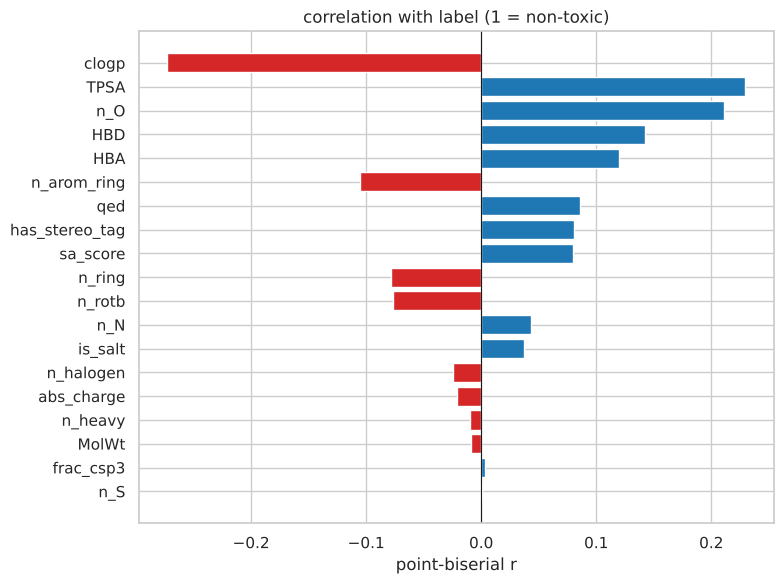

In [29]:
from scipy.stats import pointbiserialr, spearmanr
feat_all = pd.concat([df[desc_cols], sf], axis=1)
rows = []
for c in feat_all.columns:
    r, p = pointbiserialr(df["label"], feat_all[c]); rs, _ = spearmanr(df["label"], feat_all[c])
    rows.append((c, r, p, rs))
corr_label = pd.DataFrame(rows, columns=["특성", "점이연 r", "p", "Spearman"]).set_index("특성")
corr_label = corr_label.reindex(corr_label["점이연 r"].abs().sort_values(ascending=False).index)
display(corr_label.round(4))

plt.figure(figsize=(8, 6))
cl = corr_label["점이연 r"]
plt.barh(cl.index[::-1], cl.values[::-1], color=["tab:blue" if v > 0 else "tab:red" for v in cl.values[::-1]])
plt.axvline(0, c="k", lw=0.8); plt.title("correlation with label (1 = non-toxic)"); plt.xlabel("point-biserial r")
plt.tight_layout(); plt.show()

In [30]:
# fingerprint 비트별 phi 계수
Fv = df[fp_cols].values.astype(float); yv = df["label"].values.astype(float)
sd = Fv.std(0)
phi = pd.Series(np.where(sd > 0, ((Fv - Fv.mean(0)) * (yv - yv.mean())[:, None]).mean(0) / (sd * yv.std()), 0), index=fp_cols)
summ = pd.DataFrame({k: {"|phi| ≥ 0.1": int((phi[phi.index.str.startswith(k)].abs() >= 0.1).sum()),
                         "|phi| ≥ 0.2": int((phi[phi.index.str.startswith(k)].abs() >= 0.2).sum()),
                         "최대 |phi|": round(phi[phi.index.str.startswith(k)].abs().max(), 3)} for k in ["ecfp", "fcfp", "ptfp"]}).T
display(summ)
print("|phi| 상위 비트:", phi.abs().sort_values(ascending=False).head(8).round(3).to_dict())

,|phi| ≥ 0.1,|phi| ≥ 0.2,최대 |phi|
ecfp,20.0,0.0,0.188
fcfp,23.0,0.0,0.179
ptfp,25.0,0.0,0.160


|phi| 상위 비트: {'ecfp_807': 0.188, 'fcfp_146': 0.179, 'fcfp_18': 0.177, 'ecfp_650': 0.177, 'ecfp_893': 0.168, 'ecfp_425': 0.167, 'fcfp_822': 0.164, 'ptfp_284': 0.16}


#### 5차 실험: 라벨 상관이 매우 약한 변수 제외
10-2에서 라벨과의 상관이 |r| < 0.05로 매우 약하게 나온 6개(is_salt, n_halogen, abs_charge, MolWt, frac_csp3, n_S)를 최종 컬럼에서 빼면 성능이 달라지는지 확인 (1차 실험과 같은 CV 설정)

In [31]:
# 상관이 매우 약한(|r| < 0.05) 변수를 빼면 성능이 달라지는지 (최종 컬럼 기준, 1차 실험과 같은 CV 설정)
exp5 = pd.read_csv("eda_results/exp5_results.csv")
t5 = exp5.pivot(index="variant", columns="model", values="f1_mean")
s5 = exp5.pivot(index="variant", columns="model", values="f1_std")
display((t5.round(4).astype(str) + " ± " + s5.round(4).astype(str)))

model,LightGBM,LogReg,MLP
variant,,,
최종 - 약한 상관 6개,0.8172 ± 0.0056,0.7853 ± 0.0079,0.8033 ± 0.0099
"최종 1,042개",0.8179 ± 0.0064,0.7859 ± 0.0086,0.8015 ± 0.0072


### 10-2 결과
| 특성 | 점이연 r | 해석 |
|---|---|---|
| clogp | -0.273 | 가장 강함. 지용성이 높을수록 독성 쪽 |
| TPSA | +0.229 | 극성 표면적이 클수록 비독성 쪽 |
| n_O | +0.211 | 산소 원자가 많을수록 비독성 쪽 (TPSA와 겹쳐 10-1에서 이미 제거, 비교용 표시) |
| HBD / HBA | +0.143 / +0.120 | 수소결합 공여·수용체가 많을수록 비독성 쪽 |
| n_arom_ring | -0.105 | 방향족 고리가 많을수록 독성 쪽 |
| qed, sa_score, has_stereo_tag, n_ring, n_rotb | 0.077~0.086 | 약함 |
| n_N, is_salt, n_halogen, abs_charge | 0.02~0.04 | 매우 약함 |
| MolWt, n_heavy, frac_csp3, n_S | 0.01 미만 (p > 0.3) | 직선적 관계 없음 |

- Spearman 상관도 순서와 크기가 거의 같아 이상치 영향은 작음
- fingerprint 비트: |phi| 0.1 이상인 비트가 ECFP 20개, FCFP 23개, PTFP 25개이고 0.2를 넘는 비트는 없음 (최대 ecfp_807 0.188, fcfp_146 0.179)
- 최종 선택한 ECFP·FCFP 비트(2% 필터)에 |phi| 0.1 이상인 ECFP·FCFP 비트 43개가 모두 포함됨 → 라벨을 보지 않는 필터가 신호가 강한 비트를 버리지 않았음
- 개별 상관은 모두 약한데(최대 0.27) 조합 모델의 AUC는 0.88 → 독성은 변수 하나가 아니라 여러 변수의 조합으로 설명됨. 상관계수 순위만으로 컬럼을 고르지 않고 조합 실험(13단계)을 한 이유

5차 실험 결과: 상관이 매우 약한 6개(is_salt, n_halogen, abs_charge, MolWt, frac_csp3, n_S)를 뺀 결과
| | LightGBM F1 | LogReg F1 | MLP F1 |
|---|---|---|---|
| 최종 1,042개 | 0.818 | 0.786 | 0.801 |
| 약한 상관 6개 제외 (1,036개) | 0.817 | 0.785 | 0.803 |

- 세 모델 모두 차이가 표준편차(0.006~0.010) 안 → 빼도 이득이 없고 손해도 없음
- 결정: 유지. 이 6개를 고른 기준이 train 전체 라벨로 계산한 상관이라, 이걸로 컬럼을 빼면 "라벨 기반 선택은 fold 안에서만" 원칙에 어긋남. 6개를 빼서 얻는 이득(컬럼 0.6% 감소)도 거의 없음

## 11. 인코딩·변환 필요성 점검
목적: 원핫 인코딩, 스케일링, 로그 변환 같은 처리가 필요한 컬럼이 있는지 컬럼 타입별로 확인

In [32]:
R_cols = [c for c in sf.columns if c not in ["n_heavy", "n_N", "n_O"]]
rows = [
    ("SMILES", 1, str(train["SMILES"].dtype), train["SMILES"].nunique()),
    ("ecfp/fcfp/ptfp", len(fp_cols), "int (0/1)", int(np.unique(train[fp_cols].values).size)),
    ("MolWt, clogp, sa_score, qed", 4, "float", int(train[desc_cols].nunique().min())),
]
for c in R_cols:
    rows.append((c, 1, str(sf[c].dtype), sf[c].nunique()))
enc = pd.DataFrame(rows, columns=["컬럼", "개수", "타입", "고유값 수(최소)"])
display(enc)
print("문자열(object/str) 컬럼:", [c for c in train.columns if train[c].dtype == object or str(train[c].dtype).startswith("str")])
print("파생 변수 왜도(절대값 1 초과):", sf[R_cols].skew().loc[lambda s: s.abs() > 1].round(2).to_dict())

,컬럼,개수,타입,고유값 수(최소)
0,SMILES,1,str,8349
1,ecfp/fcfp/ptfp,3072,int (0/1),2
2,"MolWt, clogp, sa_score, qed",4,float,5870
3,is_salt,1,int64,2
4,has_stereo_tag,1,int64,2
5,n_halogen,1,int64,11
6,n_S,1,int64,5
7,abs_charge,1,int64,4
8,n_ring,1,int64,11
9,n_arom_ring,1,int64,8


문자열(object/str) 컬럼: ['SMILES', 'can', 'can_noiso', 'parent']
파생 변수 왜도(절대값 1 초과): {'is_salt': 5.56, 'n_halogen': 1.35, 'n_S': 1.64, 'abs_charge': 8.66, 'HBD': 1.54}


### 11단계 결과
| 컬럼 그룹 | 상태 | 처리 |
|---|---|---|
| SMILES | 분자마다 다른 문자열(8,349개 모두 고유) → 범주형이 아니라 식별자 | 모델 입력에서 제외. 파생 변수 계산과 그룹 키(parent·scaffold)에만 사용 |
| fingerprint 3,072개 | 이미 0/1 이진값 (부분구조 유무를 원핫처럼 표현한 형태) | 인코딩 불필요. 12단계에서 컬럼 정리만 수행 |
| descriptor 4종 | 연속형, 왜도 모두 1 미만 | 로그 변환 불필요 |
| RDKit 파생 개수형(HBD·HBA·n_ring 등) | 순서가 있는 정수. HBD(1.54)·n_halogen(1.35)·n_S(1.64)·abs_charge(8.66)는 왜도가 1을 넘지만 값 범위가 작은 정수(최대 고유값 20개) | 크기 자체가 의미 있으므로 원핫 대신 숫자 그대로 사용. 로그 변환은 하지 않고 선형·MLP에서 표준화만 적용 |
| is_salt, has_stereo_tag | 0/1 | 그대로 사용 |
| block2, parent, scaffold | 행 블록·분자 그룹 정보 | 예측에 쓰면 안 되는 메타 정보 → 모델 입력 제외, CV 그룹 키로만 사용 |

결정: 원핫 인코딩이 필요한 범주형 컬럼은 없음. 스케일링은 트리 모델에는 불필요하고, 로지스틱 회귀·MLP에서만 연속형 변수에 StandardScaler를 CV fold 안에서 적용 (fold 밖에서 하면 검증 데이터 정보가 섞임)

## 12. Fingerprint 사용 방식 정리
목적: fingerprint를 원본 3,072개 그대로 쓰지 않고, 정보가 없거나 겹치는 비트를 라벨을 보지 않는 기준으로 정리

- 켜짐 비율: 한 비트 컬럼에서 값이 1인 분자의 비율. 1% 미만(그 부분구조를 가진 분자가 80개 미만)이거나 99% 초과(거의 모든 분자가 가짐)면 분자를 구분하는 데 쓸모가 적음
- 아래 정리는 모두 라벨을 쓰지 않으므로 train 전체에 적용해도 누수가 없음 (라벨 기반 비트 선택은 Day2에 fold 안에서)

In [33]:
def fp_filter(frame, cols, lo):
    r = frame[cols].mean()
    if lo == 0:
        return list(r[(r > 0) & (r < 1)].index)
    return list(r[(r >= lo) & (r <= 1 - lo)].index)

def prune_dup_corr(frame, cols, thr=0.95):
    cols = list(frame[cols].T.drop_duplicates().index)          # 완전히 같은 컬럼 제거
    M = np.abs(np.corrcoef(frame[cols].values.T))
    drop = set()
    for i in range(len(cols)):
        if cols[i] in drop:
            continue
        for j in np.where(M[i, i+1:] >= thr)[0] + i + 1:       # 상관 0.95 이상이면 뒤쪽 컬럼 제거
            drop.add(cols[j])
    return [c for c in cols if c not in drop]

rows = []
for name, cols in [("ECFP", ecfp_cols), ("FCFP", fcfp_cols), ("PTFP", ptfp_cols)]:
    k = fp_filter(df, cols, 0.01)
    M = np.abs(np.corrcoef(df[k].values.T)); iu = np.triu_indices_from(M, 1)
    rows.append((name, len(cols), len(fp_filter(df, cols, 0)), len(fp_filter(df, cols, 0.005)), len(k),
                 len(fp_filter(df, cols, 0.02)), int((M[iu] >= 0.95).sum()), len(prune_dup_corr(df, k))))
display(pd.DataFrame(rows, columns=["종류", "원본", "상수 제거", "0.5% 필터", "1% 필터", "2% 필터",
                                    "1% 필터 후 상관≥0.95 쌍", "1% 필터+중복·고상관 정리"]))

,종류,원본,상수 제거,0.5% 필터,1% 필터,2% 필터,1% 필터 후 상관≥0.95 쌍,1% 필터+중복·고상관 정리
0,ECFP,1024,1024,1015,930,644,0,930
1,FCFP,1024,1024,790,601,383,0,601
2,PTFP,1024,975,864,824,753,89,772


In [34]:
# ECFP와 FCFP가 서로 같은 정보를 담고 있는지: 한쪽 비트마다 다른 쪽에서 가장 상관이 높은 비트를 찾음
def max_cross_corr(A, B):
    a = df[A].values.astype(float); b = df[B].values.astype(float)
    a = (a - a.mean(0)) / a.std(0); b = (b - b.mean(0)) / b.std(0)
    return np.abs(a.T @ b / len(df)).max(1)

E1, F1, P1 = fp_filter(df, ecfp_cols, 0.01), fp_filter(df, fcfp_cols, 0.01), fp_filter(df, ptfp_cols, 0.01)
for a_name, A, b_name, B in [("ECFP", E1, "FCFP", F1), ("FCFP", F1, "ECFP", E1), ("PTFP", P1, "ECFP", E1)]:
    mx = max_cross_corr(A, B)
    print(f"{a_name} 비트의 {b_name} 최대 상관: 중앙값 {np.median(mx):.3f}, 0.95 이상 {int((mx >= 0.95).sum())}개")

ECFP 비트의 FCFP 최대 상관: 중앙값 0.341, 0.95 이상 0개


FCFP 비트의 ECFP 최대 상관: 중앙값 0.399, 0.95 이상 0개


PTFP 비트의 ECFP 최대 상관: 중앙값 0.311, 0.95 이상 0개


### 12단계 결과
| 종류 | 원본 | 1% 필터 후 | 중복·고상관 정리 후 | 특징 |
|---|---|---|---|---|
| ECFP | 1,024 | 930 | 930 | 비트 간 상관 0.95 이상 쌍 없음 |
| FCFP | 1,024 | 601 | 601 | 희귀 비트가 많아 1% 필터에서 423개 제거 |
| PTFP | 1,024 | 824 | 772 | 조밀한 지문이라 완전 중복·상관 0.95 이상 비트가 많음 (52개 추가 제거) |

- ECFP와 FCFP는 한쪽 비트마다 다른 쪽에서 가장 비슷한 비트를 찾아도 상관 중앙값 0.34~0.40, 0.95 이상은 0개 → 서로 다른 정보라 둘 다 후보
- fingerprint 사용 방식 결정
  - 값은 0/1 그대로 사용 (스케일링·PCA 하지 않음. PCA는 희소 이진값에 맞지 않고 비트 해석이 불가능해짐)
  - ECFP·FCFP는 1% 필터, PTFP는 1% 필터 + 중복·고상관 정리
  - 어떤 종류를 넣을지는 13단계 조합 실험으로 결정, 필터 기준은 15단계(0~2%)와 15-1단계(0~20% 스윕)에서 결정 → 최종 2%

## 13. 데이터셋 조합 실험 (1차)
목적: 10~12단계에서 정리한 변수 그룹을 조합해, 모델 종류와 관계없이 안정적으로 F1이 높은 조합을 찾음

변수 그룹
| 기호 | 내용 | 컬럼 수 |
|---|---|---|
| D | 제공 descriptor 4종 (MolWt, clogp, sa_score, qed) | 4 |
| R | RDKit 파생 12종 (10단계 정리 후) | 12 |
| E | ECFP (1% 필터) | 930 |
| F | FCFP (1% 필터) | 601 |
| P | PTFP (1% 필터 + 중복·고상관 정리) | 772 |

실험 설계
| 항목 | 설정 | 이유 |
|---|---|---|
| 데이터 | 3단계에서 정리한 8,000행 | 중복·충돌 제거 |
| 검증 | StratifiedGroupKFold 5-fold × seed 2 = 10회, 그룹 = parent | 같은 분자가 학습·검증에 나뉘는 누수 방지, 한 번의 분할에 우연히 맞는 조합 방지 |
| 모델 | LightGBM(트리), 로지스틱 회귀(선형, C=0.05), MLP(신경망, 은닉층 128) | 최종 모델 계열이 달라도 통하는 조합 선택 |
| 하이퍼파라미터 | 모든 조합에 같은 고정값 | 튜닝 효과를 빼고 데이터 조합 차이만 비교 |
| 지표 | F1(threshold 0.5) 평균 ± 표준편차, ROC AUC | 과제 지표 F1 + threshold와 무관한 AUC |

선택 규칙: 모델마다 1위 조합의 F1에서 그 표준편차를 뺀 값 이상인 조합을 "1위와 차이 없음"으로 보고, 세 모델 모두에서 차이 없는 조합 중 컬럼이 가장 적은 조합을 선택

In [35]:
import os, time
import lightgbm as lgb
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

DESC = desc_cols
RDKIT_KEEP = ["TPSA", "HBD", "HBA", "n_rotb", "n_ring", "n_arom_ring", "frac_csp3",
              "n_halogen", "n_S", "abs_charge", "is_salt", "has_stereo_tag"]
CONT = DESC + [c for c in RDKIT_KEEP if c not in binary_cols]

def make_model(kind, cont_cols, seed):
    if kind == "LightGBM":
        return lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, colsample_bytree=0.3,
                                  subsample=0.8, subsample_freq=1, verbose=-1, random_state=seed, n_jobs=2)
    pre = ColumnTransformer([("sc", StandardScaler(), cont_cols)], remainder="passthrough")   # fold 안에서만 fit
    if kind == "LogReg":
        return make_pipeline(pre, LogisticRegression(C=0.05, max_iter=3000))
    return make_pipeline(pre, MLPClassifier((128,), alpha=1e-3, early_stopping=True, max_iter=100, random_state=seed))

def run_cv(Xall, cols, y, groups, kind, seeds=(0, 1), n_splits=5):
    cont_cols = [c for c in cols if c in CONT]
    X = Xall[cols]; f1s, aucs = [], []
    for seed in seeds:
        for tr, va in StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed).split(X, y, groups):
            m = make_model(kind, cont_cols, seed).fit(X.iloc[tr], y[tr])
            p = m.predict_proba(X.iloc[va])[:, 1]
            f1s.append(f1_score(y[va], p >= 0.5)); aucs.append(roc_auc_score(y[va], p))
    return dict(f1_mean=np.mean(f1s), f1_std=np.std(f1s), auc_mean=np.mean(aucs), auc_std=np.std(aucs), n_cols=len(cols))

E = fp_filter(df, ecfp_cols, 0.01); F = fp_filter(df, fcfp_cols, 0.01)
P = prune_dup_corr(df, fp_filter(df, ptfp_cols, 0.01))
Xall = pd.concat([df[fp_cols + DESC], sf[RDKIT_KEEP]], axis=1)
y_all = df["label"].values; groups_parent = pd.factorize(df["parent"])[0]
SETS = {"D": DESC, "D+R": DESC + RDKIT_KEEP, "E": E, "F": F, "P": P, "E+F": E + F, "E+F+P": E + F + P,
        "E+F+P+D": E + F + P + DESC, "E+F+D+R": E + F + DESC + RDKIT_KEEP, "E+F+P+D+R": E + F + P + DESC + RDKIT_KEEP}
print({k: len(v) for k, v in SETS.items()})

{'D': 4, 'D+R': 16, 'E': 930, 'F': 601, 'P': 772, 'E+F': 1531, 'E+F+P': 2303, 'E+F+P+D': 2307, 'E+F+D+R': 1547, 'E+F+P+D+R': 2319}


In [36]:
# 실행 시간이 약 25분 걸려 결과를 eda_results/exp1_results.csv에 저장해 두고 불러옴. 다시 돌리려면 RUN_EXP1 = True
RUN_EXP1 = False
os.makedirs("eda_results", exist_ok=True)
path1 = "eda_results/exp1_results.csv"
if RUN_EXP1 or not os.path.exists(path1):
    rows = []
    for kind in ["LightGBM", "LogReg", "MLP"]:
        for name, cols in SETS.items():
            r = run_cv(Xall, cols, y_all, groups_parent, kind); r.update(model=kind, set=name); rows.append(r)
    pd.DataFrame(rows).to_csv(path1, index=False)
exp1 = pd.read_csv(path1)

order = list(SETS)
tbl = exp1.pivot(index="set", columns="model", values="f1_mean").loc[order]
std = exp1.pivot(index="set", columns="model", values="f1_std").loc[order]
auc = exp1.pivot(index="set", columns="model", values="auc_mean").loc[order]
show = pd.DataFrame({"컬럼 수": exp1.drop_duplicates("set").set_index("set").loc[order, "n_cols"]})
for m in ["LightGBM", "LogReg", "MLP"]:
    show[f"{m} F1"] = tbl[m].map("{:.4f}".format) + " ± " + std[m].map("{:.4f}".format)
    show[f"{m} AUC"] = auc[m].round(4)
display(show)

,컬럼 수,LightGBM F1,LightGBM AUC,LogReg F1,LogReg AUC,MLP F1,MLP AUC
set,,,,,,,
D,4,0.6526 ± 0.0075,0.6587,0.6716 ± 0.0066,0.6662,0.6707 ± 0.0070,0.6908
D+R,16,0.7563 ± 0.0060,0.8038,0.7043 ± 0.0091,0.7175,0.7287 ± 0.0124,0.7626
E,930,0.7931 ± 0.0082,0.8489,0.7502 ± 0.0076,0.7978,0.7758 ± 0.0142,0.8329
F,601,0.7989 ± 0.0061,0.8590,0.7586 ± 0.0085,0.8058,0.7907 ± 0.0077,0.8473
P,772,0.7965 ± 0.0067,0.8547,0.7439 ± 0.0074,0.7867,0.7753 ± 0.0152,0.8350
E+F,1531,0.8084 ± 0.0068,0.8653,0.7794 ± 0.0088,0.8317,0.7892 ± 0.0074,0.8506
E+F+P,2303,0.8118 ± 0.0070,0.8725,0.7853 ± 0.0094,0.8431,0.7954 ± 0.0095,0.8594
E+F+P+D,2307,0.8204 ± 0.0078,0.8830,0.7901 ± 0.0068,0.8491,0.8016 ± 0.0116,0.8628
E+F+D+R,1547,0.8189 ± 0.0079,0.8816,0.7884 ± 0.0093,0.8434,0.8047 ± 0.0095,0.8644


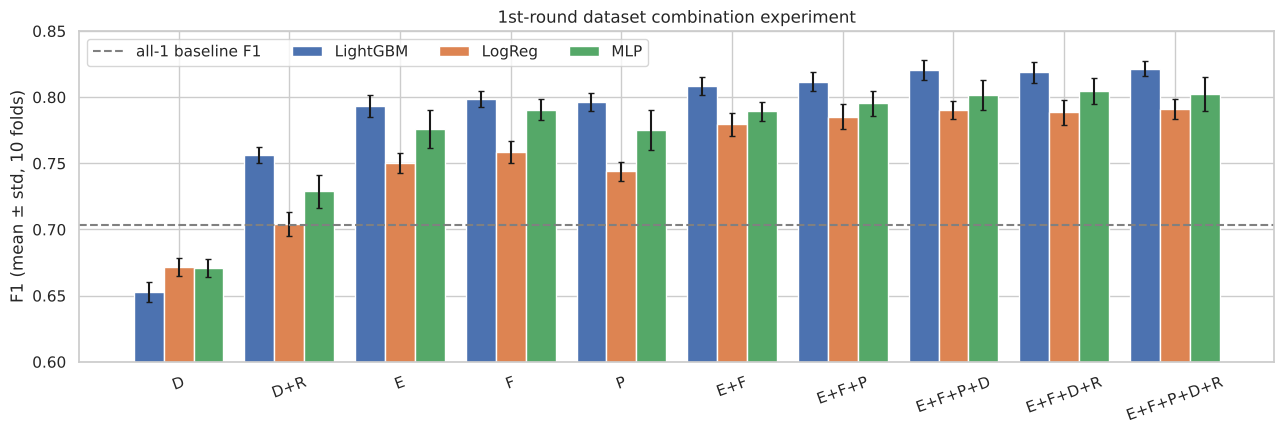

In [37]:
fig, ax = plt.subplots(figsize=(13, 4.5))
x = np.arange(len(order)); w = 0.27
for i, m in enumerate(["LightGBM", "LogReg", "MLP"]):
    ax.bar(x + (i - 1) * w, tbl[m], w, yerr=std[m], capsize=2, label=m)
ax.axhline(f1_score(df["label"], np.ones(len(df))), ls="--", c="gray", label="all-1 baseline F1")
ax.set_xticks(x); ax.set_xticklabels(order, rotation=20); ax.set_ylim(0.6, 0.85); ax.set_ylabel("F1 (mean ± std, 10 folds)")
ax.legend(ncol=4); ax.set_title("1st-round dataset combination experiment"); plt.tight_layout(); plt.show()

In [38]:
# 선택 규칙 적용
ok = {}
for m in ["LightGBM", "LogReg", "MLP"]:
    best = tbl[m].idxmax(); cut = tbl.loc[best, m] - std.loc[best, m]
    ok[m] = set(tbl.index[tbl[m] >= cut])
    print(f"{m}: 1위 {best} ({tbl.loc[best, m]:.4f}), 기준선 {cut:.4f} → 차이 없는 조합 {sorted(ok[m], key=order.index)}")
common = set.intersection(*ok.values())
n_cols = exp1.drop_duplicates("set").set_index("set")["n_cols"]
choice = min(common, key=lambda s: n_cols[s])
print("세 모델 모두에서 1위와 차이 없는 조합:", sorted(common, key=order.index))
print("그중 컬럼이 가장 적은 조합:", choice, f"({n_cols[choice]}개)")

LightGBM: 1위 E+F+P+D+R (0.8216), 기준선 0.8159 → 차이 없는 조합 ['E+F+P+D', 'E+F+D+R', 'E+F+P+D+R']
LogReg: 1위 E+F+P+D+R (0.7909), 기준선 0.7834 → 차이 없는 조합 ['E+F+P', 'E+F+P+D', 'E+F+D+R', 'E+F+P+D+R']
MLP: 1위 E+F+D+R (0.8047), 기준선 0.7952 → 차이 없는 조합 ['E+F+P', 'E+F+P+D', 'E+F+D+R', 'E+F+P+D+R']
세 모델 모두에서 1위와 차이 없는 조합: ['E+F+P+D', 'E+F+D+R', 'E+F+P+D+R']
그중 컬럼이 가장 적은 조합: E+F+D+R (1547개)


### 13단계 결과
| 조합 | 컬럼 수 | LightGBM F1 | LogReg F1 | MLP F1 |
|---|---|---|---|---|
| D | 4 | 0.653 | 0.672 | 0.671 |
| D+R | 16 | 0.756 | 0.704 | 0.729 |
| E | 930 | 0.793 | 0.750 | 0.776 |
| F | 601 | 0.799 | 0.759 | 0.791 |
| P | 772 | 0.797 | 0.744 | 0.775 |
| E+F | 1,531 | 0.808 | 0.779 | 0.789 |
| E+F+P | 2,303 | 0.812 | 0.785 | 0.795 |
| E+F+P+D | 2,307 | 0.820 | 0.790 | 0.802 |
| E+F+D+R | 1,547 | 0.819 | 0.788 | 0.805 (1위) |
| E+F+P+D+R | 2,319 | 0.822 (1위) | 0.791 (1위) | 0.802 |

(10회 CV 평균, 표준편차는 0.006~0.015. 전부 1로 찍는 베이스라인 F1은 0.703)

해석
- descriptor 4종(D)만으로는 베이스라인(0.703)보다도 낮음. RDKit 파생(R)을 더하면 세 모델 모두 크게 오름 (LightGBM 0.653 → 0.756)
- fingerprint 한 종류만 쓸 때는 FCFP가 세 모델 모두에서 가장 좋음. ECFP와 합치면 LightGBM(+0.010)·LogReg(+0.021)는 오르고 MLP는 비슷함(-0.002). D·R까지 더한 조합에서는 세 모델 모두 PTFP 없이도 1위권
- fingerprint에 D·R을 더하면 세 모델 모두 추가 상승 (E+F 대비 +0.009~0.016)
- PTFP는 E+F+D+R에 더해도 F1 변화가 -0.002~+0.003으로 표준편차 안 → 772개 컬럼을 늘릴 근거가 없음
- 선택 규칙 적용 결과: 세 모델 모두에서 1위와 차이 없는 조합은 E+F+P+D, E+F+D+R, E+F+P+D+R이고, 그중 컬럼이 가장 적은 E+F+D+R(1,547개) 선택

## 14. 1차 실험 기준 잠정 선정 컬럼
| 그룹 | 선정 컬럼 | 개수 | 선정 근거 |
|---|---|---|---|
| ECFP | ecfp 중 켜짐 비율 1~99% 비트 | 930 | 단독 F1 0.750~0.793, FCFP와 정보가 겹치지 않음(최대 상관 중앙값 0.34) |
| FCFP | fcfp 중 켜짐 비율 1~99% 비트 | 601 | 단독 fingerprint 중 세 모델 모두 1위(F1 0.759~0.799), ECFP와 합치면 LightGBM·LogReg 추가 상승 |
| descriptor | MolWt, clogp, sa_score, qed | 4 | clogp 단일 AUC 0.339(5단계), fingerprint에 더하면 성능 상승 |
| RDKit 파생 | TPSA, HBD, HBA, n_rotb, n_ring, n_arom_ring, frac_csp3, n_halogen, n_S, abs_charge, is_salt, has_stereo_tag | 12 | D 대비 F1 +0.03~0.10, TPSA 단일 AUC 0.638(9단계), 다중공선성 정리 후 VIF 10 미만 |
| 합계 | | 1,547 | 세 모델 모두에서 1위와 차이 없는 조합 중 최소 컬럼 |

제외한 컬럼과 이유
| 제외 | 이유 |
|---|---|
| PTFP 전체 | 추가 시 F1 변화가 표준편차 안(-0.002~+0.003)인데 컬럼 772개 증가 |
| n_heavy, n_N, n_O | MolWt·TPSA와 겹침(상관 0.97, R² 0.845), VIF 15 이상 |
| 켜짐 비율 1% 미만·99% 초과 비트 | 분자 구분에 쓸모가 적음 (이후 15·15-1단계에서 기준을 2%로 확정) |
| SMILES, parent, scaffold, block2 | 식별자·메타 정보 (CV 그룹 키로만 사용) |

아직 확인할 것 (2차·3차 실험)
- fingerprint 필터 기준: 필터 없음 / 0.5% / 1% / 2%
- qed 제거 효과 (다른 변수로 계산되는 파생 지표)
- 다중공선성 정리(n_heavy·n_N·n_O 제거)가 실제 성능을 해치지 않는지
- 같은 골격을 같은 fold로 묶는 scaffold CV에서도 선택 결과가 유지되는지

## 15. 2차 실험: 기준 조합(E+F+D+R) 세부 조정
목적: 1차에서 고른 E+F+D+R을 기준으로, 아직 근거 없이 정한 세 가지를 실험으로 확인

| 확인 항목 | 비교한 변형 | 왜 확인하나 |
|---|---|---|
| fingerprint 필터 기준 | 상수 비트만 제거 / 0.5% / 1% / 2% | 1%는 관례일 뿐이고, 희귀 비트에도 신호가 있을 수 있음(6단계 fcfp_780 등) |
| qed 포함 여부 | 기준 vs qed 제외 | qed는 다른 변수 8개로 계산되는 파생 지표(10단계) |
| 다중공선성 정리 효과 | 기준 vs n_heavy·n_N·n_O 다시 추가 | 정리하면서 실제로 잃은 정보가 없는지 |

설계는 1차와 동일 (parent 그룹 5-fold × seed 2, 3개 모델, 고정 하이퍼파라미터), 선택 규칙도 동일

In [39]:
path2 = "eda_results/exp2_results.csv"
exp2 = pd.read_csv(path2)          # 생성 코드: run_cv를 아래 변형별로 실행 (1차와 같은 함수)
var_order = ["필터 없음(상수 비트만 제거)", "필터 0.5%", "필터 1% (기준)", "필터 2%", "기준 - qed", "기준 + 제거했던 n_heavy·n_N·n_O"]
t2 = exp2.pivot(index="variant", columns="model", values="f1_mean").loc[var_order]
s2 = exp2.pivot(index="variant", columns="model", values="f1_std").loc[var_order]
a2 = exp2.pivot(index="variant", columns="model", values="auc_mean").loc[var_order]
show2 = pd.DataFrame({"컬럼 수": exp2.drop_duplicates("variant").set_index("variant").loc[var_order, "n_cols"]})
for m in ["LightGBM", "LogReg", "MLP"]:
    show2[f"{m} F1"] = t2[m].map("{:.4f}".format) + " ± " + s2[m].map("{:.4f}".format)
    show2[f"{m} AUC"] = a2[m].round(4)
display(show2)

def ties(t, s, rows):
    res = {}
    for m in ["LightGBM", "LogReg", "MLP"]:
        sub = t.loc[rows, m]; best = sub.idxmax(); cut = sub[best] - s.loc[best, m]
        res[m] = set(sub.index[sub >= cut])
    return set.intersection(*res.values())

filt_rows = var_order[:4]
common_f = ties(t2, s2, filt_rows)
print("필터 기준: 세 모델 모두 1위와 차이 없는 기준 →", [r for r in filt_rows if r in common_f])
print("그중 컬럼이 가장 적은 기준 → 필터 2%")

,컬럼 수,LightGBM F1,LightGBM AUC,LogReg F1,LogReg AUC,MLP F1,MLP AUC
variant,,,,,,,
필터 없음(상수 비트만 제거),2064,0.8199 ± 0.0071,0.8820,0.7903 ± 0.0101,0.8469,0.7989 ± 0.0109,0.8600
필터 0.5%,1821,0.8181 ± 0.0079,0.8806,0.7896 ± 0.0099,0.8460,0.8012 ± 0.0067,0.8633
필터 1% (기준),1547,0.8189 ± 0.0079,0.8816,0.7884 ± 0.0093,0.8434,0.8047 ± 0.0095,0.8644
필터 2%,1043,0.8202 ± 0.0070,0.8811,0.7853 ± 0.0085,0.8356,0.8039 ± 0.0115,0.8627
기준 - qed,1546,0.8198 ± 0.0079,0.8813,0.7887 ± 0.0093,0.8430,0.8020 ± 0.0087,0.8620
기준 + 제거했던 n_heavy·n_N·n_O,1550,0.8211 ± 0.0079,0.8822,0.7896 ± 0.0094,0.8437,0.8029 ± 0.0087,0.8594


필터 기준: 세 모델 모두 1위와 차이 없는 기준 → ['필터 없음(상수 비트만 제거)', '필터 0.5%', '필터 1% (기준)', '필터 2%']
그중 컬럼이 가장 적은 기준 → 필터 2%


### 15단계 결과
| 변형 | 컬럼 수 | LightGBM F1 | LogReg F1 | MLP F1 |
|---|---|---|---|---|
| 상수 비트만 제거 | 2,064 | 0.820 | 0.790 | 0.799 |
| 필터 0.5% | 1,821 | 0.818 | 0.790 | 0.801 |
| 필터 1% (1차 기준) | 1,547 | 0.819 | 0.788 | 0.805 |
| 필터 2% | 1,043 | 0.820 | 0.785 | 0.804 |
| qed 제외 | 1,546 | 0.820 | 0.789 | 0.802 |
| n_heavy·n_N·n_O 다시 추가 | 1,550 | 0.821 | 0.790 | 0.803 |

(표준편차 0.007~0.012)

- 필터 기준: 네 기준 모두 세 모델에서 1위와 표준편차 안 → 같은 선택 규칙으로 컬럼이 가장 적은 2%(1,043개) 선택. 컬럼이 1,547 → 1,043개로 33% 줄어도 성능이 유지됨. 단, LogReg AUC는 1% 대비 0.008 낮아 3차에서 1%와 다시 비교
- qed: 빼도 F1 차이 ±0.003 → 다른 변수로 계산되는 파생 지표이므로 제외
- 다중공선성 정리: 제거했던 3개를 다시 넣어도 성능이 오르지 않음(+0.001 이하) → 정리하면서 잃은 정보 없음, 제거 유지

### 15-1. 4차 실험: fingerprint 필터 기준 스윕 (2차 실험 후속)
2차 실험은 2%까지만 확인해서 "어디서부터 성능이 떨어지는지"는 알 수 없었음. 기준을 0~20%까지 올려 가며 F1 변화를 보고, 성능이 떨어지기 직전 지점을 선택

- 기준 조합: ECFP·FCFP(필터) + MolWt·clogp·sa_score + RDKit 12 (최종 구성과 동일)
- 필터는 위아래 대칭 (예: 5%면 켜짐 비율 5% 이상 95% 이하 비트만 남김)
- 설계: 3개 모델 × parent 그룹 5-fold × seed 2
- 선택 규칙: 세 모델 모두에서 1위와 표준편차 안에 드는 기준 중 가장 큰 기준 (= 성능이 꺾이기 직전)

,n_ecfp,n_fcfp,n_cols,LightGBM F1,LogReg F1,MLP F1
필터(%),,,,,,
0.0,1024,1024,2063,0.8215 ± 0.0076,0.7908 ± 0.0099,0.8008 ± 0.0077
0.5,1015,790,1820,0.8189 ± 0.0079,0.7897 ± 0.0097,0.8014 ± 0.0125
1.0,930,601,1546,0.8198 ± 0.0079,0.7887 ± 0.0093,0.8020 ± 0.0087
2.0,644,383,1042,0.8179 ± 0.0064,0.7859 ± 0.0086,0.8015 ± 0.0072
3.0,463,276,754,0.8174 ± 0.0092,0.7804 ± 0.0070,0.8057 ± 0.0083
4.0,343,224,582,0.8176 ± 0.0070,0.7743 ± 0.0076,0.8003 ± 0.0092
5.0,262,189,466,0.8179 ± 0.0071,0.7718 ± 0.0082,0.8095 ± 0.0121
7.5,155,116,286,0.8131 ± 0.0056,0.7501 ± 0.0077,0.8027 ± 0.0085
10.0,112,90,217,0.8112 ± 0.0065,0.7407 ± 0.0097,0.7961 ± 0.0069


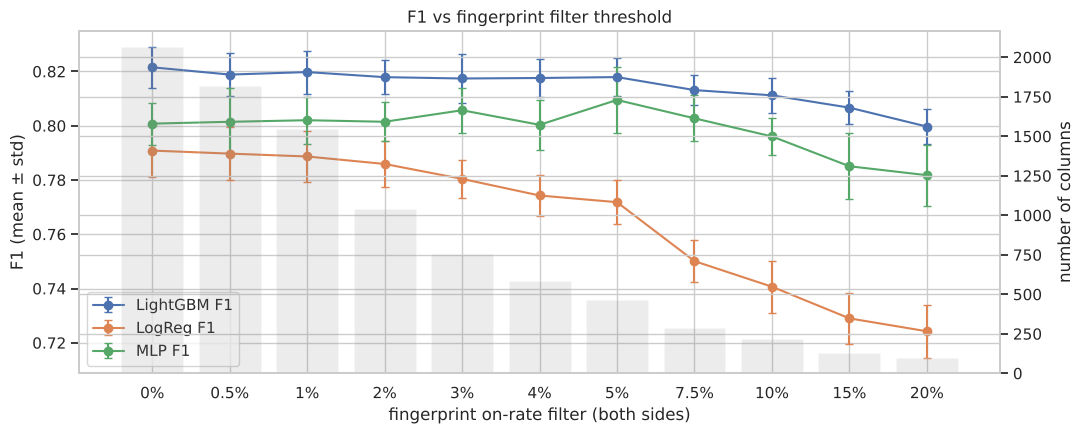

LightGBM: 1위 0% (0.8215), 기준선 0.8139 → 차이 없는 기준 [0.0, 0.5, 1.0, 2.0, 3.0, 4.0, 5.0]
LogReg: 1위 0% (0.7908), 기준선 0.7810 → 차이 없는 기준 [0.0, 0.5, 1.0, 2.0]
MLP: 1위 5% (0.8095), 기준선 0.7974 → 차이 없는 기준 [0.0, 0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 7.5]
세 모델 모두 차이 없는 기준: [0.0, 0.5, 1.0, 2.0] → 선택: 2%


In [40]:
exp6 = pd.read_csv("eda_results/exp6_results.csv")
exp6["필터(%)"] = exp6["threshold"] * 100
tbl6 = exp6.pivot(index="필터(%)", columns="model", values="f1_mean")
std6 = exp6.pivot(index="필터(%)", columns="model", values="f1_std")
ncol6 = exp6.drop_duplicates("threshold").set_index("필터(%)")[["n_ecfp", "n_fcfp", "n_cols"]]
show6 = ncol6.copy()
for m in ["LightGBM", "LogReg", "MLP"]:
    show6[f"{m} F1"] = tbl6[m].map("{:.4f}".format) + " ± " + std6[m].map("{:.4f}".format)
display(show6)

fig, ax1 = plt.subplots(figsize=(11, 4.5))
xs = np.arange(len(tbl6))
for m in ["LightGBM", "LogReg", "MLP"]:
    ax1.errorbar(xs, tbl6[m], yerr=std6[m], marker="o", capsize=3, label=f"{m} F1")
ax1.set_xticks(xs); ax1.set_xticklabels([f"{v:g}%" for v in tbl6.index]); ax1.set_xlabel("fingerprint on-rate filter (both sides)")
ax1.set_ylabel("F1 (mean ± std)")
ax2 = ax1.twinx(); ax2.bar(xs, ncol6["n_cols"], alpha=0.15, color="gray", label="n columns"); ax2.set_ylabel("number of columns")
ax1.legend(loc="lower left"); ax1.set_title("F1 vs fingerprint filter threshold"); plt.tight_layout(); plt.show()

ok6 = {}
for m in ["LightGBM", "LogReg", "MLP"]:
    best = tbl6[m].idxmax(); cut = tbl6.loc[best, m] - std6.loc[best, m]
    ok6[m] = set(tbl6.index[tbl6[m] >= cut])
    print(f"{m}: 1위 {best:g}% ({tbl6.loc[best, m]:.4f}), 기준선 {cut:.4f} → 차이 없는 기준 {sorted(ok6[m])}")
common6 = set.intersection(*ok6.values())
print("세 모델 모두 차이 없는 기준:", sorted(common6), "→ 선택:", f"{max(common6):g}%")

### 15-1 결과 (4차 실험)
| 필터 | 컬럼 수 | LightGBM F1 | LogReg F1 | MLP F1 |
|---|---|---|---|---|
| 0% (상수만 제거) | 2,063 | 0.822 (1위) | 0.791 (1위) | 0.801 |
| 0.5% | 1,820 | 0.819 | 0.790 | 0.801 |
| 1% | 1,546 | 0.820 | 0.789 | 0.802 |
| 2% | 1,042 | 0.818 | 0.786 | 0.801 |
| 3% | 754 | 0.817 | 0.780 ✗ | 0.806 |
| 4% | 582 | 0.818 | 0.774 ✗ | 0.800 |
| 5% | 466 | 0.818 | 0.772 ✗ | 0.810 (1위) |
| 7.5% | 286 | 0.813 ✗ | 0.750 ✗ | 0.803 |
| 10% | 217 | 0.811 ✗ | 0.741 ✗ | 0.796 ✗ |
| 15% | 127 | 0.807 ✗ | 0.729 ✗ | 0.785 ✗ |
| 20% | 94 | 0.800 ✗ | 0.724 ✗ | 0.782 ✗ |

(✗ = "1위 F1 − 1위 표준편차" 기준선 밖. 기준선: LightGBM 0.814, LogReg 0.781, MLP 0.797)

- 모델마다 꺾이는 지점이 다름
  - LightGBM: 0~5%는 평평(0.817~0.822), 7.5%부터 하락
  - LogReg: 3%부터 하락, 20%에서 0.724까지 떨어져 필터에 가장 민감. 선형 모델은 희귀 비트 하나하나의 기여에 더 의존하기 때문
  - MLP: 5%에서 오히려 가장 높고(컬럼이 줄어 과적합 감소) 10%부터 하락
- 세 모델 모두 기준선 안인 구간은 0~2% → 그중 가장 큰 2%(1,042개) 선택. 2차 실험의 2% 선택이 스윕에서도 유지됨
- 판단: 7.5% LightGBM처럼 기준선과 0.001 이내로 갈리는 경계 사례가 있어, 이 기준은 절대값이 아니라 "모델 종류와 무관하게 손실이 없는 가장 작은 컬럼 수"를 고르는 판단 근거로 사용
- 남겨 둔 옵션: Day2에 최종 모델이 트리 계열로 정해지면 5%(466개)도 LightGBM·MLP에서는 손실 없이 쓸 수 있음

## 16. 3차 실험: scaffold CV 재검증
목적: 지금까지는 같은 분자(parent)만 같은 fold로 묶었음. 8단계에서 같은 골격(scaffold) 분자끼리 라벨이 몰려 있는 것을 확인했기 때문에, 같은 골격을 같은 fold로 묶어 "처음 보는 골격"에서도 선택 결과가 유지되는지 확인

| 후보 | 구성 | 컬럼 수 |
|---|---|---|
| 최종 후보 | E+F(2% 필터) + D(qed 제외) + R | 1,042 |
| 1차 잠정 | E+F(1% 필터) + D + R | 1,547 |
| 최대 조합 | E+F(1%) + P + D + R | 2,319 |

검증: StratifiedGroupKFold 5-fold × seed 2, 그룹 = scaffold. 최종 후보는 parent CV 결과도 함께 표시

In [41]:
exp3 = pd.read_csv("eda_results/exp3_results.csv")
exp4 = pd.read_csv("eda_results/exp4_results.csv")
cand_order = ["최종 후보: E+F(2%)+D(qed 제외)+R", "1차 잠정: E+F(1%)+D+R", "최대 조합: E+F(1%)+P+D+R"]
t3 = exp3.pivot(index="set", columns="model", values="f1_mean").loc[cand_order]
s3 = exp3.pivot(index="set", columns="model", values="f1_std").loc[cand_order]
a3 = exp3.pivot(index="set", columns="model", values="auc_mean").loc[cand_order]
show3 = pd.DataFrame({"컬럼 수": exp3.drop_duplicates("set").set_index("set").loc[cand_order, "n_cols"]})
for m in ["LightGBM", "LogReg", "MLP"]:
    show3[f"{m} F1"] = t3[m].map("{:.4f}".format) + " ± " + s3[m].map("{:.4f}".format)
    show3[f"{m} AUC"] = a3[m].round(4)
print("scaffold 그룹 CV"); display(show3)

common3 = ties(t3, s3, cand_order)
print("세 모델 모두 1위와 차이 없는 후보:", [c for c in cand_order if c in common3])

cmp = pd.DataFrame({
    "parent CV F1": exp4.set_index("model")["f1_mean"],
    "scaffold CV F1": t3.loc[cand_order[0]],
})
cmp["차이"] = cmp["scaffold CV F1"] - cmp["parent CV F1"]
print("최종 후보: parent CV vs scaffold CV"); display(cmp.round(4))

scaffold 그룹 CV


,컬럼 수,LightGBM F1,LightGBM AUC,LogReg F1,LogReg AUC,MLP F1,MLP AUC
set,,,,,,,
최종 후보: E+F(2%)+D(qed 제외)+R,1042,0.7898 ± 0.0083,0.8469,0.7622 ± 0.0062,0.8055,0.7738 ± 0.0106,0.8259
1차 잠정: E+F(1%)+D+R,1547,0.7883 ± 0.0080,0.8475,0.7637 ± 0.0073,0.8109,0.7667 ± 0.0100,0.8219
최대 조합: E+F(1%)+P+D+R,2319,0.7904 ± 0.0098,0.8493,0.7632 ± 0.0108,0.8128,0.7727 ± 0.0127,0.8257


세 모델 모두 1위와 차이 없는 후보: ['최종 후보: E+F(2%)+D(qed 제외)+R', '1차 잠정: E+F(1%)+D+R', '최대 조합: E+F(1%)+P+D+R']
최종 후보: parent CV vs scaffold CV


,parent CV F1,scaffold CV F1,차이
model,,,
LightGBM,0.8179,0.7898,-0.0281
LogReg,0.7859,0.7622,-0.0237
MLP,0.8015,0.7738,-0.0277


### 16단계 결과
| 후보 | 컬럼 수 | LightGBM F1 | LogReg F1 | MLP F1 |
|---|---|---|---|---|
| 최종 후보 | 1,042 | 0.790 | 0.762 | 0.774 (1위) |
| 1차 잠정 | 1,547 | 0.788 | 0.764 (1위) | 0.767 |
| 최대 조합 | 2,319 | 0.790 (1위) | 0.763 | 0.773 |

(scaffold CV, 표준편차 0.006~0.013)

- 세 후보 모두 세 모델에서 1위와 표준편차 안 → 컬럼이 가장 적은 최종 후보(1,042개)가 scaffold CV에서도 선택됨. 2% 필터의 LogReg 손실도 scaffold CV에서는 0.002로 표준편차 안
- 최종 후보의 F1은 parent CV 대비 scaffold CV에서 0.024~0.028 낮음 (LightGBM 0.818 → 0.790, LogReg 0.786 → 0.762, MLP 0.801 → 0.774) → 처음 보는 골격의 분자는 예측이 더 어려움. Day2에 predict_input의 골격이 train에 얼마나 있는지 보고 어느 CV 점수를 기준으로 할지 정함

## 17. 최종 컬럼 선정과 전처리
### 최종 학습 컬럼 (1,042개)
| 그룹 | 컬럼 | 개수 | 선정 근거 (정량 지표) |
|---|---|---|---|
| ECFP | 켜짐 비율 2~98% 비트 | 644 | 단독 F1 0.750~0.793(13단계), FCFP와 정보 안 겹침(최대 상관 중앙값 0.34, 12단계) |
| FCFP | 켜짐 비율 2~98% 비트 | 383 | 단독 fingerprint 중 세 모델 모두 1위(F1 0.759~0.799), ECFP와 합치면 LightGBM +0.010·LogReg +0.021 (MLP는 -0.002로 비슷) |
| descriptor | MolWt, clogp, sa_score | 3 | clogp 단일 AUC 0.339로 가장 강한 descriptor(5단계), fingerprint에 D·R 추가 시 +0.009~0.016 |
| RDKit 파생 | TPSA, HBD, HBA, n_rotb, n_ring, n_arom_ring, frac_csp3, n_halogen, n_S, abs_charge, is_salt, has_stereo_tag | 12 | D 대비 F1 +0.03~0.10(13단계), TPSA 단일 AUC 0.638(9단계), 정리 후 VIF 최대 9.2(10단계) |

### 제외한 컬럼
| 제외 | 근거 |
|---|---|
| PTFP 1,024개 | 추가해도 F1 변화 -0.002~+0.003으로 표준편차 안(13단계), scaffold CV에서도 차이 없음(16단계) |
| 켜짐 비율 2% 미만·98% 초과 ECFP·FCFP 비트 | 4차 실험(0~20% 스윕)에서 세 모델 모두 손실 없는 가장 큰 기준이 2%(15-1단계). 3%부터 LogReg 하락 |
| qed | 다른 변수 8개로 계산되는 파생 지표(R² 0.853), 제외해도 F1 ±0.003(15단계) |
| n_heavy, n_N, n_O | MolWt·TPSA와 겹침(상관 0.972, R² 0.845, VIF 15~44), 다시 넣어도 이득 없음(15단계) |
| SMILES, parent, scaffold | 식별자·그룹 키 (CV 그룹 지정에만 사용) |

### 학습 데이터 전처리 규칙
1. parent(가장 큰 조각 + 입체 제거) 계산 → 라벨이 충돌하는 37그룹(81행) 제외, parent당 1행 → 8,000행
2. RDKit 파생 12개 계산
3. 위 1,042개 컬럼만 선택 (fingerprint 목록은 train 기준으로 고정해 predict_input에도 같은 목록 사용)
4. 인코딩 없음. 스케일링은 로지스틱 회귀·MLP에서만 연속형 15개에 StandardScaler (CV fold 안에서 fit)
5. CV: StratifiedGroupKFold(shuffle=True), 그룹 = parent (scaffold CV도 함께 확인)

In [42]:
import json
E_final = fp_filter(df, ecfp_cols, 0.02); F_final = fp_filter(df, fcfp_cols, 0.02)
final_features = E_final + F_final + ["MolWt", "clogp", "sa_score"] + RDKIT_KEEP
print("ECFP", len(E_final), "/ FCFP", len(F_final), "/ 합계", len(final_features))

from preprocess import load_feature_columns
print("feature_columns.json과 일치:", load_feature_columns("feature_columns.json") == final_features)

# preprocess.py로 train.csv를 처음부터 다시 처리했을 때 이 노트북의 결과와 같은지 확인
from preprocess import preprocess_train
d_pp, X_pp, y_pp, g_pp = preprocess_train("train.csv")
X_nb = pd.concat([df[E_final + F_final + ["MolWt", "clogp", "sa_score"]], sf[RDKIT_KEEP]], axis=1)
print("행 수:", len(X_pp), "/ 컬럼 수:", X_pp.shape[1])
print("노트북 결과와 값 일치:", np.allclose(X_pp.values.astype(float), X_nb[final_features].values.astype(float)),
      "/ 라벨 일치:", (y_pp == df["label"].values).all())

out = pd.concat([d_pp[["SMILES", "parent", "scaffold"]], X_pp, d_pp[["label"]]], axis=1)
out.to_csv("train_preprocessed.csv", index=False)
print("저장: train_preprocessed.csv", out.shape)

ECFP 644 / FCFP 383 / 합계 1042
feature_columns.json과 일치: True


행 수: 8000 / 컬럼 수: 1042
노트북 결과와 값 일치: True / 라벨 일치: True


저장: train_preprocessed.csv (8000, 1046)


### 산출물 (mini_project 폴더)
| 파일 | 내용 |
|---|---|
| `train_preprocessed.csv` | 8,000행 × (SMILES, parent, scaffold, 학습 컬럼 1,042개, label) |
| `feature_columns.json` | 최종 컬럼을 종류별(ecfp·fcfp·descriptor·rdkit)로 한 번씩 저장, order 순서로 이어 붙이면 학습 컬럼 1,042개. 전처리 규칙 메모 포함 |
| `preprocess.py` | train·predict_input 공통 전처리 함수 (`preprocess_train`, `preprocess_predict`) |
| `eda_results/exp1~6_results.csv` | exp1 = 1차, exp2 = 2차, exp3·exp4 = 3차(scaffold CV·최종 후보 parent CV), exp5 = 5차, exp6 = 4차 실험 결과 |

Day2 사용 예
```python
from preprocess import preprocess_train, preprocess_predict
train_df, X, y, groups = preprocess_train("train.csv")
pred_df, X_pred = preprocess_predict("predict_input.csv")   # 927행 그대로 유지
```

---
## 전체 요약: 데이터 → EDA → 실험 → 컬럼 선정

| 흐름 | 단계 | 핵심 결과 | 결정 |
|---|---|---|---|
| 데이터 이해 | 1. 품질·행 순서 | 결측 0, MolWt 정렬 블록 2개(7,737 / 612행) | CV shuffle 필수 |
| | 2. 정합성 | descriptor·fingerprint 모두 RDKit 계산값 | 같은 방식으로 파생 변수 생성 |
| | 3. 중복·충돌 | parent 기준 중복 312행, 라벨 충돌 37그룹 | 충돌 제외·parent당 1행 → 8,000행, parent 그룹 CV |
| | 4. 라벨 | 비독성 54.2% | 베이스라인 F1 0.703 |
| 변수와 독성의 관계 | 5. descriptor | clogp AUC 0.339(가장 강함), MolWt 무관 | clogp 핵심 |
| | 6. fingerprint | FDR 유의 비트 다수, FCFP 비트가 가장 강함 | 비트 정리 후 사용 |
| | 7·8. 유사도·골격 | 이웃 라벨 일치율 0.757, 골격 순도 0.817 | KNN 베이스라인, scaffold CV 비교 |
| | 9. RDKit 파생 | TPSA AUC 0.638, HBD 0.590 | 파생 변수 후보 |
| 컬럼 정리 | 10-1. 상관·다중공선성 | MolWt–n_heavy 0.97, TPSA ≈ n_N+n_O(R² 0.845), qed는 8개 속성의 파생 지표 | n_heavy·n_N·n_O 제거, VIF 최대 9.2 |
| | 10-2. 특성–라벨 상관 | clogp -0.27, TPSA +0.23, HBD +0.14, 개별 상관 최대 0.27·phi 최대 0.19 | 5차 실험: 약한 상관 6개는 빼도 차이 없어 유지 |
| | 11. 인코딩 | 범주형 없음, fingerprint는 이미 0/1 | 원핫 불필요, 스케일링은 선형·MLP fold 안에서만 |
| | 12. fingerprint 정리 | ECFP–FCFP 정보 안 겹침, PTFP 고상관 89쌍 | 필터 + PTFP 중복 정리 |
| 실험 | 13. 1차 실험: 조합 | 3개 모델 × 10개 조합 × 10회 CV | E+F+D+R(1,547개) 잠정 선정, PTFP 효과 없음 |
| | 15. 2차 실험: 조정 | 필터 없음~2% 차이 없음, qed·다중공선성 정리 영향 없음 | 2% 필터, qed 제외 |
| | 15-1. 4차 실험: 필터 스윕 0~20% | LightGBM 7.5%·LogReg 3%·MLP 10%부터 하락, 세 모델 공통 안전 구간 0~2% | 2% 확정 |
| | 16. 3차 실험: scaffold CV | 세 후보 모두 차이 없음, scaffold CV는 parent CV보다 0.024~0.028 낮음 | 최종 후보 유지 |
| 선정 | 17. 최종 컬럼 | ECFP 644 + FCFP 383 + descriptor 3 + RDKit 12 | 1,042개, train_preprocessed.csv·preprocess.py 저장 |

### 실험 차수 정리
| 차수 | 내용 | 위치 | 결과 파일 | 결론 |
|---|---|---|---|---|
| 1차 | 변수 그룹 10개 조합 비교 (3개 모델 × 10회 그룹 CV) | 13·14단계 | exp1 | E+F+D+R 잠정 선정, PTFP 효과 없음 |
| 2차 | 필터 0~2%, qed 제외, 다중공선성 정리 효과 | 15단계 | exp2 | 2% 필터, qed 제외, 정리 유지 |
| 3차 | 후보 3개를 scaffold CV로 재검증 + 최종 후보 parent CV | 16단계 | exp3, exp4 | 최종 후보 유지, parent CV 대비 0.024~0.028 하락 |
| 4차 | 필터 기준 0~20% 스윕 | 15-1단계 | exp6 | 세 모델 공통 안전 구간 0~2% → 2% 확정 |
| 5차 | 라벨 상관이 약한 변수 6개 제외 | 10-2단계 | exp5 | 차이 없음 → 유지 |

- 4차는 2차 실험(필터 기준)의 후속이라 15단계 바로 아래(15-1)에, 5차는 특성–라벨 상관 분석의 일부라 10-2에 배치